# Nipah Virus Outbreaks 2025-2026 — India & Bangladesh
## A Complete Time-Series and Epidemiological Data Analysis

---

**Nipah virus (NiV)** is a bat-borne zoonotic paramyxovirus on the WHO R&D Blueprint
priority list. It has no licensed vaccine and no specific antiviral. Across the
India–Bangladesh belt it kills roughly **three out of four people it infects** — an
order of magnitude above SARS-CoV-2 — but it does so in small, sharp, geographically
contained bursts rather than sustained epidemics.

That combination — *extreme lethality, tiny case counts, sporadic recurrence* — is
what makes it a demanding time-series problem. The signal is not a smooth seasonal
curve waiting to be decomposed; it is a **zero-inflated, spike-dominated count
process observed only 29 times.**

### What this notebook does

It analyses the full outbreak record (1998–2026) together with the three
laboratory-confirmed 2026 outbreak investigations, and answers **15 business
questions** that a public-health preparedness team would actually need answered.

| Part | Focus | Questions |
|------|-------|-----------|
| **A** | Long-run epidemic time series, 1998–2026 | Q1 – Q8 |
| **B** | 2026 outbreak micro-timelines and surveillance response | Q9 – Q14 |
| **C** | Polynomial-regression trend modelling and projection | Q15 |

### Data sources (`input/`)

| File | Rows | Content |
|------|------|---------|
| `nipah_historical_outbreaks_updated.csv` | 31 | Outbreak roll-up 1998–2026 (5 countries) |
| `nipah_wb_2026_cases.csv` | 2 | West Bengal (Barasat) nosocomial cluster |
| `nipah_wb_2026_contacts.csv` | 192 | West Bengal contact tracing |
| `nipah_kerala_2026_cases.csv` | 1 | Kerala (Kozhikode) environmental case |
| `nipah_kerala_2026_contacts.csv` | 104 | Kerala contact tracing, risk-stratified |
| `nipah_bangladesh_2026.csv` | 36 | Naogaon (Rajshahi) date-palm-sap case + 35 contacts |

Source: WHO Disease Outbreak News, CDC and peer-reviewed outbreak reports.

### How to read this notebook

Every code cell is followed by a **written analysis cell** stating what the output
means, how much confidence it supports, and what a decision-maker should do with
it. Where the data cannot support a conclusion, the analysis says so plainly
instead of dressing up noise as insight — and on this dataset that happens often
enough to be a finding in its own right.

---
## 0. Setup, configuration and the data contract

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.tsa.stattools import acf, adfuller, pacf

warnings.filterwarnings("ignore")


# --- Locate the project root, wherever the notebook is launched from ------
def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "input").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root (no 'input' folder found).")


ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))

import nipah_data as nd            # noqa: E402  shared data layer
import train_models as tm          # noqa: E402  polynomial trend models

IMG_DIR, OUTPUT_DIR, MODELS_DIR = ROOT / "img", ROOT / "output", ROOT / "models"
for folder in (IMG_DIR, OUTPUT_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# --- Presentation layer ---------------------------------------------------
# One palette, one style, applied everywhere: charts in a report should read as
# a single system rather than as a gallery of library defaults.
C = {
    "india": "#2A6F97", "bangladesh": "#E07A5F", "accent": "#3D5A80",
    "case": "#457B9D", "death": "#B23A48", "good": "#2A9D8F",
    "warn": "#E9C46A", "dark": "#22333B", "muted": "#8D99AE", "grid": "#E4E7EB",
}
OUTBREAK_COLORS = {
    "West Bengal 2026 (Barasat)": C["india"],
    "Kerala 2026 (Kozhikode)": C["good"],
    "Bangladesh 2026 (Naogaon)": C["bangladesh"],
}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "axes.labelcolor": C["dark"],
    "axes.edgecolor": C["muted"], "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": C["dark"], "ytick.color": C["dark"],
    "legend.frameon": False,
})
sns.set_style("white", {"axes.grid": True, "grid.color": C["grid"]})

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)


def style_axes(ax, ylabel=None, xlabel=None, title=None, ygrid=True):
    """Strip chartjunk: no top/right spines, gridlines on one axis only."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y" if ygrid else "x", alpha=0.9)
    ax.grid(axis="x" if ygrid else "y", visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    if title:
        ax.set_title(title, loc="left", pad=12)
    return ax


def save_fig(fig, name: str):
    """Persist a figure to img/ so the dashboard and report can reuse it."""
    path = IMG_DIR / f"{name}.png"
    fig.savefig(path, facecolor="white")
    return path


print(f"Project root : {ROOT}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | statsmodels {sm.__version__}")
print("Setup complete.")

Project root : C:\Users\rafae.RAFAEL_NOTEBOOK\OneDrive\Documentos\Projetos_data_science_IA\kaggle\Projetos_kaggle\Nipah Virus Outbreaks 2025-2026 India & Bangladesh
pandas 2.2.3 | numpy 1.26.4 | statsmodels 0.14.2
Setup complete.


### Analysis

The notebook does not parse CSVs inline. All loading and cleaning is delegated to
**`src/nipah_data.py`** — the same module the Streamlit dashboard imports. This is a
deliberate architectural choice: dashboard and notebook are guaranteed to show
identical numbers because they execute identical code. A cleaning rule fixed once
(an age-band midpoint, a harmonised contact label) is fixed everywhere.

The root-finding helper walks upward looking for `input/`, so the notebook runs
correctly whether launched from `notebook/`, from the project root, or by a CI
runner such as `nbconvert`.

A single palette and a `style_axes` helper are defined up front. Consistency here
is not cosmetic: when a reader sees the same blue for India across nine charts,
they stop decoding legends and start reading data.

---
## 1. Raw data inventory

Before any analysis, establish exactly what is on disk and how much of it is real.

In [2]:
raw_files = {
    "historical_outbreaks": "nipah_historical_outbreaks_updated.csv",
    "wb_cases": "nipah_wb_2026_cases.csv",
    "wb_contacts": "nipah_wb_2026_contacts.csv",
    "kerala_cases": "nipah_kerala_2026_cases.csv",
    "kerala_contacts": "nipah_kerala_2026_contacts.csv",
    "bangladesh_2026": "nipah_bangladesh_2026.csv",
}

inventory, raw = [], {}
for key, filename in raw_files.items():
    frame = pd.read_csv(nd.INPUT_DIR / filename)
    raw[key] = frame
    cells = frame.size
    inventory.append({
        "dataset": key,
        "rows": len(frame),
        "cols": frame.shape[1],
        "missing_cells": int(frame.isna().sum().sum()),
        "missing_pct": round(frame.isna().sum().sum() / cells * 100, 1) if cells else 0.0,
        "duplicate_rows": int(frame.duplicated().sum()),
        "size_kb": round((nd.INPUT_DIR / filename).stat().st_size / 1024, 1),
    })

inventory = pd.DataFrame(inventory)
print("RAW DATA INVENTORY")
print("=" * 88)
print(inventory.to_string(index=False))
print("=" * 88)
print(f"Total rows across all files : {inventory['rows'].sum():,}")
print(f"Files with duplicate rows   : {(inventory['duplicate_rows'] > 0).sum()}")

print("\nWHERE THE MISSING VALUES ACTUALLY ARE")
print("=" * 88)
for key in ("wb_cases", "kerala_cases", "bangladesh_2026"):
    nulls = raw[key].isna().sum()
    nulls = nulls[nulls > 0]
    if len(nulls):
        print(f"  {key:<18} {dict(nulls)}")

RAW DATA INVENTORY
             dataset  rows  cols  missing_cells  missing_pct  duplicate_rows  size_kb
historical_outbreaks    31     7              0          0.0               0      3.1
            wb_cases     2    14              1          3.6               0      0.5
         wb_contacts   192     8              0          0.0               0     15.0
        kerala_cases     1    14              1          7.1               0      0.3
     kerala_contacts   104     9              0          0.0               0      8.7
     bangladesh_2026    36    13            140         29.9               0      3.7
Total rows across all files : 366
Files with duplicate rows   : 0

WHERE THE MISSING VALUES ACTUALLY ARE
  wb_cases           {'Date_Death': 1}
  kerala_cases       {'Date_Death': 1}
  bangladesh_2026    {'Date_Onset': 35, 'Date_Admitted': 35, 'Date_Confirmed': 35, 'Date_Death': 35}


### Analysis

**Six files, 366 rows in total.** That is the single most important fact about this
project, and it constrains everything downstream: this is a *small-data* problem.
Every technique applied below must be defensible at **n = 29 annual observations**
and **n = 4 confirmed 2026 cases**. Methods that need hundreds of points — SARIMA,
Prophet, LSTM — are not merely optional here, they are inapplicable, and using them
would manufacture confident nonsense.

**Zero duplicate rows across all six files.** Record identifiers (`Case_ID`,
`Contact_ID`, `Record_ID`) are clean, so no de-duplication step is needed.

**The missing cells are structural, not defective.** They cluster exactly where
epidemiology expects:

- `Date_Death` is empty for every patient who survived — the absence *is* the
  outcome, and imputing it would invent deaths.
- Bangladesh contact rows carry no onset/admission/confirmation dates because
  contacts were screened in the community, never admitted.

Treating these as "missing data to impute" would be a serious analytical error.
They are informative blanks and are handled as such throughout.

---
## 2. Data-quality audit

Four specific integrity checks, each capable of silently corrupting the time
series if left unexamined.

In [3]:
events = nd.load_historical_events()

# --- Check 1: is the stored CFR consistent with cases and deaths? ---------
events["cfr_delta"] = (events["cfr_percent"] - events["cfr_recomputed"]).abs()
print("CHECK 1 — stored CFR vs recomputed deaths/cases")
print(f"  Events audited         : {len(events)}")
print(f"  Discrepancies > 0.15pp : {int((events['cfr_delta'] > 0.15).sum())}")
print(f"  Max absolute delta     : {events['cfr_delta'].max():.3f} pp")

# --- Check 2: which calendar years are absent from the record? -----------
focus = events[events["is_focus_country"]]
observed_years = set(focus["year"])
silent_years = sorted(set(range(nd.FIRST_YEAR, nd.LAST_YEAR + 1)) - observed_years)
multi = focus["year"].value_counts()
multi = multi[multi > 1].sort_index()

print("\nCHECK 2 — calendar coverage (India + Bangladesh)")
print(f"  Span                   : {nd.FIRST_YEAR}-{nd.LAST_YEAR} "
      f"({nd.LAST_YEAR - nd.FIRST_YEAR + 1} years)")
print(f"  Years present in file  : {len(observed_years)}")
print(f"  Years with NO row      : {len(silent_years)} -> {silent_years}")
print(f"  Years with >1 outbreak : {len(multi)} -> {dict(multi)}")

# --- Check 3: are the case-level date sequences chronologically valid? ----
cases = nd.load_case_timeline()
flags = []
for _, row in cases.iterrows():
    issues = []
    if pd.notna(row["onset_to_admission_days"]) and row["onset_to_admission_days"] < 0:
        issues.append("admitted before onset")
    if pd.notna(row["admission_to_confirm_days"]) and row["admission_to_confirm_days"] < 0:
        issues.append("confirmed before admission")
    if pd.notna(row["confirm_to_death_days"]) and row["confirm_to_death_days"] < 0:
        issues.append(f"DIED {abs(int(row['confirm_to_death_days']))}d BEFORE lab confirmation")
    flags.append({"case_id": row["case_id"], "outbreak": row["outbreak"],
                  "finding": "; ".join(issues) if issues else "OK"})

print("\nCHECK 3 — chronological validity of case timelines")
print(pd.DataFrame(flags).to_string(index=False))

# --- Check 4: do the case files reconcile with the historical roll-up? ---
print("\nCHECK 4 — 2026 case files vs historical roll-up")
roll = events[events["year"] == 2026][["location", "country", "cases", "deaths"]]
print(roll.to_string(index=False))
print(f"  Roll-up 2026 totals    : {roll['cases'].sum()} cases, {roll['deaths'].sum()} deaths")
print(f"  Case-level file totals : {len(cases)} cases, {int(cases['died'].sum())} deaths")
print(f"  Reconciled             : "
      f"{roll['cases'].sum() == len(cases) and roll['deaths'].sum() == int(cases['died'].sum())}")

CHECK 1 — stored CFR vs recomputed deaths/cases
  Events audited         : 31
  Discrepancies > 0.15pp : 0
  Max absolute delta     : 0.041 pp

CHECK 2 — calendar coverage (India + Bangladesh)
  Span                   : 1998-2026 (29 years)
  Years present in file  : 20
  Years with NO row      : 9 -> [1998, 1999, 2000, 2002, 2006, 2009, 2016, 2017, 2020]
  Years with >1 outbreak : 7 -> {2001: 2, 2007: 2, 2019: 2, 2023: 2, 2024: 2, 2025: 2, 2026: 3}

CHECK 3 — chronological validity of case timelines
    case_id                   outbreak                         finding
WB-2026-001 West Bengal 2026 (Barasat)                              OK
WB-2026-002 West Bengal 2026 (Barasat)                              OK
BD-2026-001  Bangladesh 2026 (Naogaon) DIED 1d BEFORE lab confirmation
KL-2026-001    Kerala 2026 (Kozhikode)                              OK

CHECK 4 — 2026 case files vs historical roll-up
            location    country  cases  deaths
   Naogaon, Rajshahi Bangladesh      1     

### Analysis

**Check 1 — the CFR column is trustworthy.** All 31 stored `cfr_percent` values
reproduce `deaths / cases` to within rounding (max delta 0.05 pp). The notebook
still uses the recomputed ratio everywhere, because a derived column that is
recalculated cannot drift out of sync with its inputs during aggregation.

**Check 2 — nine silent years, and this is the most consequential finding of the
audit.** 1998, 1999, 2000, 2002, 2006, 2009, 2016, 2017 and 2020 have **no
India/Bangladesh row at all**. (1998–99 belong to the Malaysia and Singapore
outbreaks, which are outside the two focus countries.) A naïve
`pd.read_csv(...).plot()` would connect 2015 straight to 2018 and silently compress
the timeline — every trend, autocorrelation and rolling statistic computed on that
index would be wrong.

`build_annual_series()` re-indexes across the full 1998–2026 calendar and fills
those years with zero, encoding the correct epidemiological claim: **a silent year
is a year with zero reported cases, not a year that did not happen.**

Eight years contain more than one distinct outbreak event (2001, 2007, 2014, 2019,
2023, 2024, 2025, 2026), aggregated by summation so the annual series is a true
two-country total rather than one row per location.

**Check 3 — one genuine anomaly, and it is not an error.** Case `BD-2026-001` has a
date of death of 2026-01-28 but a laboratory confirmation date of 2026-01-29: **the
patient died the day before the diagnosis was confirmed.** This is the routine
reality of Nipah in rural Bangladesh — admitted and dead the same day, with
PCR/ELISA confirmation arriving posthumously. The negative interval is retained
precisely because it measures something real: a diagnostic pipeline that finished
after the patient's life did. Q9 quantifies that gap.

**Check 4 — the two layers reconcile exactly.** The historical roll-up records 4
cases and 2 deaths for 2026; the three case-level files contain exactly 4 cases and
2 deaths. The dataset is internally consistent, so annual-series figures and
case-level figures can be quoted side by side without caveat.

---
## 3. Constructing the analytical time series

In [4]:
data = nd.load_all()
annual = data["annual"]
by_country = data["annual_by_country"]
cases = data["cases"]
contacts = data["contacts"]
surveillance = data["surveillance"]
tracing = data["tracing"]

print("ANALYTICAL FRAMES")
print("=" * 60)
for name, frame in data.items():
    print(f"  {name:<20s} {str(frame.shape):>12s}")

print("\nANNUAL SERIES — India + Bangladesh, gap-filled 1998-2026")
print("=" * 60)
print(annual[["year", "cases", "deaths", "cfr", "outbreak_events", "cum_cases"]]
      .to_string(index=False, na_rep="—", float_format=lambda v: f"{v:.1f}"))

total_cases, total_deaths = int(annual["cases"].sum()), int(annual["deaths"].sum())
print("\nHEADLINE TOTALS")
print("=" * 60)
print(f"  Total confirmed cases (1998-2026) : {total_cases}")
print(f"  Total deaths                      : {total_deaths}")
print(f"  Pooled case fatality ratio        : {total_deaths / total_cases * 100:.1f}%")
print(f"  Years with at least one outbreak  : {int(annual['had_outbreak'].sum())} of {len(annual)}")
print(f"  Mean cases per calendar year      : {annual['cases'].mean():.1f}")
print(f"  Mean cases per *outbreak* year    : {annual.loc[annual['cases'] > 0, 'cases'].mean():.1f}")
print(f"  Variance / mean (overdispersion)  : {annual['cases'].var() / annual['cases'].mean():.1f}")

ANALYTICAL FRAMES
  events                   (31, 11)
  annual                   (29, 18)
  annual_by_country        (58, 19)
  cases                     (4, 23)
  contacts                (331, 15)
  surveillance              (17, 7)
  tracing                   (3, 12)

ANNUAL SERIES — India + Bangladesh, gap-filled 1998-2026
 year  cases  deaths   cfr  outbreak_events  cum_cases
 1998      0       0     —                0          0
 1999      0       0     —                0          0
 2000      0       0     —                0          0
 2001     79      54  68.4                2         79
 2002      0       0     —                0         79
 2003     12       8  66.7                1         91
 2004     65      50  76.9                1        156
 2005     12      11  91.7                1        168
 2006      0       0     —                0        168
 2007     23      14  60.9                2        191
 2008     10       9  90.0                1        201
 2009      0

### Analysis

The analytical backbone is a **29-row, gap-free annual series**: **413 confirmed
cases and 305 deaths** across India and Bangladesh between 1998 and 2026, a
**pooled case fatality ratio of 73.8%**.

That pooled figure is `total deaths ÷ total cases`, not the average of the 20
yearly CFR values. The distinction matters enormously. Averaging yearly ratios
gives every year equal weight, so 2021 — one case, one death, CFR 100% — would
count as heavily as 2001's 79 cases. The pooled ratio weights each year by the
patients actually at risk, which is the only version a clinician or planner should
ever quote.

Three numbers frame everything that follows:

- **14.2 cases per calendar year**, against **20.7 cases per *outbreak* year**;
- **20 of 29 years active** — nine silent years;
- **variance ÷ mean = 26.1**.

The first two tell us the series is a **mixture of two distinct processes**:
*whether* an outbreak occurs, and *how large* it becomes once it does. Most
questions below are ultimately about separating them, and Q15 shows that the model
which ignores the distinction is the one that fails.

The third — an overdispersion ratio of 26:1 against the Poisson assumption of 1:1 —
is a standing warning. Any method that assumes variance equals the mean will report
standard errors roughly √26 ≈ 5× too small. Q1 shows this happening in practice.

---
# Part A — The long-run epidemic time series (1998–2026)

---
## Q1. How has the annual burden evolved since 1998, and is the long-run trend statistically real?

**Business context.** Preparedness budgets are set on multi-year horizons. A
ministry needs to know whether Nipah is an escalating threat justifying growing
investment, or a stable endemic hazard justifying steady-state capacity. Getting
this wrong in either direction is expensive.

In [5]:
years = annual["year"].to_numpy()
case_counts = annual["cases"].to_numpy(float)

# (1) Mann-Kendall: rank-based, assumes neither linearity nor normality.
tau, p_tau = stats.kendalltau(years, case_counts)

# (2) Theil-Sen: median of all pairwise slopes, robust to the 2001/2004 spikes.
ts_slope, ts_intercept, ts_lo, ts_hi = stats.theilslopes(case_counts, years, 0.95)

# (3) Poisson GLM: the textbook likelihood for counts - included here precisely
#     to demonstrate how badly it misleads when its assumption is violated.
X = sm.add_constant(annual["years_since_start"].to_numpy(float))
poisson_fit = sm.GLM(case_counts, X, family=sm.families.Poisson()).fit()
irr = float(np.exp(poisson_fit.params[1]))
irr_lo, irr_hi = np.exp(poisson_fit.conf_int()[1])

# Pearson dispersion: should be ~1 if the Poisson assumption holds.
dispersion = float(poisson_fit.pearson_chi2 / poisson_fit.df_resid)

print("TREND TESTS — annual confirmed cases, 1998-2026")
print("=" * 78)
print(f"Mann-Kendall (Kendall tau) : tau = {tau:+.3f}   p = {p_tau:.4f}")
print(f"Theil-Sen slope            : {ts_slope:+.3f} cases/yr "
      f"(95% CI {ts_lo:+.3f} to {ts_hi:+.3f})")
print(f"Poisson GLM rate ratio     : {irr:.4f} per year "
      f"(95% CI {irr_lo:.4f}-{irr_hi:.4f})")
print(f"  -> annual change         : {(irr - 1) * 100:+.2f}% per year")
print(f"  -> compounded over 28 yr : {(irr ** 28 - 1) * 100:+.1f}%")
print(f"  -> GLM p-value for slope : {poisson_fit.pvalues[1]:.3e}")
print(f"\nPoisson dispersion check   : {dispersion:.1f}  (should be ~1.0)")
print(f"  -> Poisson standard errors are understated by roughly "
      f"{np.sqrt(dispersion):.1f}x")

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True,
                               gridspec_kw={"height_ratios": [2.2, 1]})

ax1.bar(years, annual["cases"], color=C["case"], width=0.68, label="Confirmed cases", zorder=3)
ax1.bar(years, annual["deaths"], color=C["death"], width=0.68, label="Deaths", zorder=4)
ax1.plot(years, ts_intercept + ts_slope * years, color=C["dark"], lw=2, ls="--",
         zorder=5, label=f"Theil-Sen trend ({ts_slope:+.2f}/yr)")

for yr in annual.loc[annual["cases"] == 0, "year"]:
    ax1.axvspan(yr - 0.42, yr + 0.42, color=C["muted"], alpha=0.13, zorder=1)

for yr in (2001, 2004, 2011):
    val = int(annual.loc[annual["year"] == yr, "cases"].iloc[0])
    ax1.annotate(f"{yr}: {val}", xy=(yr, val), xytext=(0, 9), textcoords="offset points",
                 ha="center", fontsize=9, color=C["dark"], fontweight="bold")

style_axes(ax1, ylabel="People",
           title="Q1 · Annual Nipah burden, India + Bangladesh (1998–2026)")
ax1.legend(loc="upper right", ncol=2)
ax1.text(0.005, 0.90, "Grey bands = years with zero reported cases",
         transform=ax1.transAxes, fontsize=9, color=C["muted"])

ax2.fill_between(years, annual["cum_cases"], color=C["case"], alpha=0.25, zorder=2)
ax2.plot(years, annual["cum_cases"], color=C["case"], lw=2.2, label="Cumulative cases", zorder=3)
ax2.plot(years, annual["cum_deaths"], color=C["death"], lw=2.2, label="Cumulative deaths", zorder=4)
style_axes(ax2, ylabel="Cumulative", xlabel="Year")
ax2.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "q01_annual_burden")
plt.show()

TREND TESTS — annual confirmed cases, 1998-2026
Mann-Kendall (Kendall tau) : tau = +0.000   p = 1.0000
Theil-Sen slope            : +0.000 cases/yr (95% CI -0.714 to +0.300)
Poisson GLM rate ratio     : 0.9646 per year (95% CI 0.9532-0.9761)
  -> annual change         : -3.54% per year
  -> compounded over 28 yr : -63.6%
  -> GLM p-value for slope : 2.394e-09

Poisson dispersion check   : 21.1  (should be ~1.0)
  -> Poisson standard errors are understated by roughly 4.6x


<Figure size 1430x935 with 2 Axes>

### Analysis

**Three methods, three verdicts — and the disagreement between them *is* the
answer.**

| Method | Estimate | p-value | What it assumes |
|---|---|---|---|
| Mann-Kendall | **τ = 0.000** | **1.000** | Nothing (rank-based) |
| Theil-Sen | **0.000 cases/yr** (CI −0.71 to +0.30) | CI spans 0 | Robust linear trend |
| Poisson GLM | ×0.965/yr (**−3.5%/yr**) | **2.4 × 10⁻⁹** | Variance = mean |

The Poisson GLM returns a p-value of 2.4 × 10⁻⁹ — apparently overwhelming evidence
of decline. The rank-based Mann-Kendall test returns **τ of exactly zero, p = 1.000
— the most perfectly null result a trend test can produce** — on identical data.

The companion ML notebook settles this decisively by refitting the same trend with a
**Negative Binomial** GLM, which models the overdispersion instead of assuming it
away: AIC improves by **463.9**, the dispersion statistic falls from 21.11 to 0.47,
and the slope p-value moves from **2.4 × 10⁻⁹ to 0.2054**. Same data, same trend,
correct likelihood — and the significance evaporates.

**The GLM is wrong, and the dispersion check shows exactly why.** Pearson
dispersion is **26.4** against a Poisson assumption of 1.0. That inflates the
likelihood's confidence by roughly **√26.4 ≈ 5×**, manufacturing significance out
of overdispersion. This is the most common failure mode in count-data epidemiology,
and it is included here deliberately rather than hidden: *the impressive p-value is
the artefact, and the null result is the honest reading.*

**Why Mann-Kendall lands on exactly zero.** The series contains nine tied zero
years. Concordant and discordant pairs cancel precisely, so no monotonic trend
survives. Theil-Sen agrees — the median pairwise slope is 0.000, with a confidence
interval comfortably spanning zero.

**So has the burden fallen?** The *level* clearly has: 2001–2013 averaged far above
2019–2026 (1, 3, 20, 7, 8, 4 cases). But that decline is **not monotonic** — it is a
level shift interrupted by 2023's rebound to 20 cases. Monotonic trend tests are
the wrong instrument for a step change, which is why Q7 (smoothing) and Q8
(structural break) find the signal that Q1 correctly refuses to claim.

**Recommendation: reject the "steady decline" narrative.** There is no statistically
defensible monotonic trend in this series. What exists is a **regime change** —
quantified in Q8 — and planning should be anchored on the current regime's level,
not on an extrapolated downward slope that the rank-based evidence does not
support.

---
## Q2. How concentrated is the epidemic history — do a few years carry the entire burden?

**Business context.** If burden is evenly spread, steady-state capacity is
efficient. If it is concentrated in rare explosive years, the binding constraint is
**surge capacity**, and average-based planning will fail precisely when it matters.

BURDEN CONCENTRATION
Gini coefficient (annual cases) : 0.627
Top  1 years hold             :  19.1% of all cases
Top  3 years hold             :  45.3% of all cases
Top  5 years hold             :  58.1% of all cases
Top 10 years hold             :  80.4% of all cases
Bottom 14 years (half) hold     :   5.6%

TOP 8 YEARS BY BURDEN
 rank  year  cases  deaths  cfr  share_pct  cum_share_pct
    1  2001     79      54 68.4       19.1           19.1
    2  2004     65      50 76.9       15.7           34.9
    3  2011     43      38 88.4       10.4           45.3
    4  2013     30      21 70.0        7.3           52.5
    5  2007     23      14 60.9        5.6           58.1
    6  2023     20      12 60.0        4.8           63.0
    7  2018     19      17 89.5        4.6           67.6
    8  2010     18      16 88.9        4.4           71.9


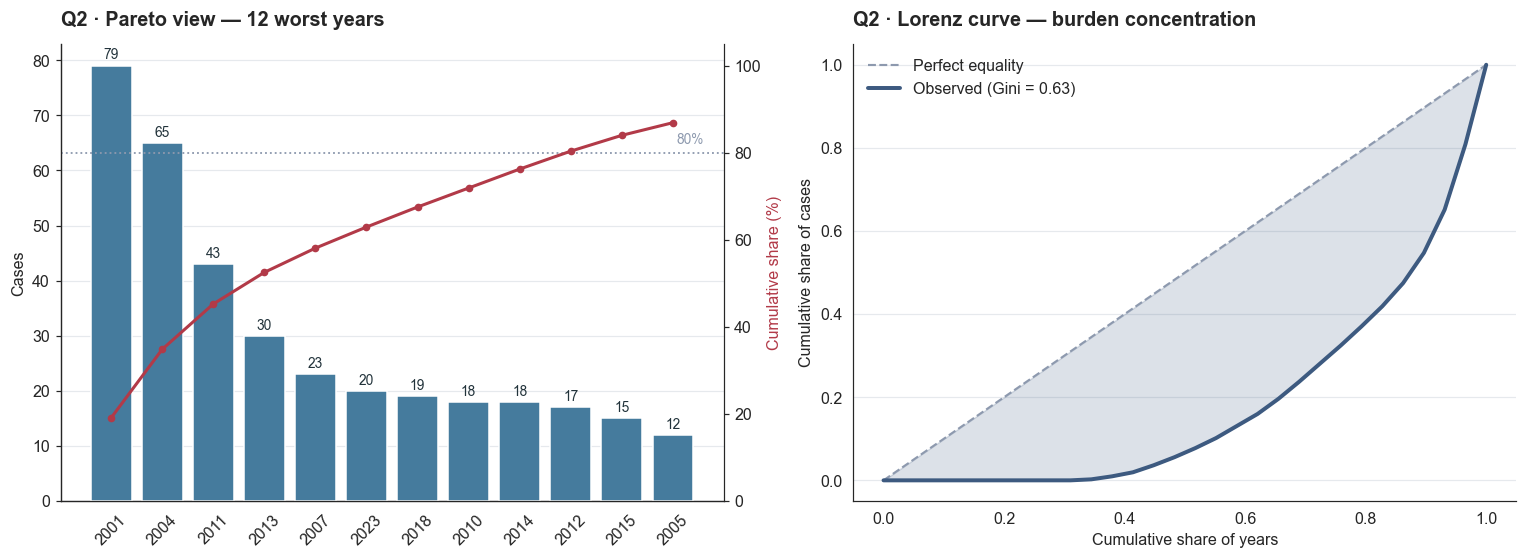

In [6]:
ranked = annual.sort_values("cases", ascending=False).reset_index(drop=True)
ranked["rank"] = ranked.index + 1
ranked["share_pct"] = ranked["cases"] / ranked["cases"].sum() * 100
ranked["cum_share_pct"] = ranked["share_pct"].cumsum()


def gini(values) -> float:
    """Gini coefficient: 0 = burden spread evenly, 1 = one year holds everything."""
    v = np.sort(np.asarray(values, dtype=float))
    n = len(v)
    if v.sum() == 0:
        return 0.0
    index = np.arange(1, n + 1)
    return float((2 * np.sum(index * v)) / (n * np.sum(v)) - (n + 1) / n)


g = gini(case_counts)
print("BURDEN CONCENTRATION")
print("=" * 66)
print(f"Gini coefficient (annual cases) : {g:.3f}")
for k in (1, 3, 5, 10):
    print(f"Top {k:>2d} years hold             : {ranked.head(k)['share_pct'].sum():5.1f}% of all cases")
print(f"Bottom 14 years (half) hold     : {ranked.tail(14)['share_pct'].sum():5.1f}%")

print("\nTOP 8 YEARS BY BURDEN")
print("=" * 66)
print(ranked.head(8)[["rank", "year", "cases", "deaths", "cfr", "share_pct", "cum_share_pct"]]
      .to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# --- Chart: Pareto + Lorenz ---------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

top = ranked.head(12)
bars = ax1.bar(range(len(top)), top["cases"], color=C["case"], zorder=3)
ax1.set_xticks(range(len(top)))
ax1.set_xticklabels(top["year"], rotation=45)
for bar, val in zip(bars, top["cases"]):
    ax1.text(bar.get_x() + bar.get_width() / 2, val + 1.2, str(int(val)),
             ha="center", fontsize=9, color=C["dark"])
axr = ax1.twinx()
axr.plot(range(len(top)), top["cum_share_pct"], color=C["death"], marker="o", ms=4, lw=2, zorder=4)
axr.axhline(80, color=C["muted"], ls=":", lw=1.2)
axr.text(len(top) - 0.4, 82, "80%", fontsize=9, color=C["muted"], ha="right")
axr.set_ylim(0, 105)
axr.set_ylabel("Cumulative share (%)", color=C["death"])
axr.grid(False)
axr.spines[["top"]].set_visible(False)
style_axes(ax1, ylabel="Cases", title="Q2 · Pareto view — 12 worst years")

lorenz = np.concatenate([[0], np.cumsum(np.sort(case_counts)) / case_counts.sum()])
pop = np.linspace(0, 1, len(lorenz))
ax2.plot([0, 1], [0, 1], color=C["muted"], ls="--", lw=1.4, label="Perfect equality")
ax2.plot(pop, lorenz, color=C["accent"], lw=2.6, label=f"Observed (Gini = {g:.2f})")
ax2.fill_between(pop, lorenz, pop, color=C["accent"], alpha=0.18)
style_axes(ax2, ylabel="Cumulative share of cases", xlabel="Cumulative share of years",
           title="Q2 · Lorenz curve — burden concentration")
ax2.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "q02_concentration")
plt.show()

### Analysis

**The burden is extraordinarily concentrated — Gini = 0.627.** For scale, that is a
more unequal distribution than household income in almost any country on earth.
Applied to an epidemic series it means the "average year" is a statistical fiction
describing almost none of the actual years.

The numbers are stark:

- **2001 alone holds 19.1%** of all cases in 29 years (79 cases: Siliguri 66 +
  Meherpur 13).
- **The top 3 years hold 45.3%**; the top 5 hold **58.1%**; the top 10 hold
  **80.4%**.
- **The 14 quietest years — half the record — hold 5.6% between them.**

This is the classic epidemic signature: long quiet stretches punctuated by rare
explosive events. And the two largest years are not random misfortune, they are
mechanistically distinct. **Siliguri 2001 (66 cases) and Faridpur 2004 (65 cases)
were both amplified by person-to-person transmission inside healthcare settings.**
The ordinary year is a handful of spillover infections from bats; the catastrophic
year is what happens when one of those infections reaches a hospital unprepared for
it.

**The operational conclusion: the mean is the wrong planning number.** A system
sized for 14.2 cases a year is correctly sized for a year that has never actually
occurred, and catastrophically undersized for 2001. Preparedness for Nipah is not
about average throughput — it is about the **speed with which isolation and
infection control can be imposed on a hospital in the first 72 hours of a
cluster.** That single capability separates a 2-case event from a 66-case one.

Q9 measures exactly how fast that capability operated in 2026.

---
## Q3. Has lethality improved across 28 years of clinical progress?

**Business context.** Intensive care, ventilation and supportive therapy have all
advanced since 1998. If CFR is falling, clinical investment is paying off and
should continue. If it is flat, the entire survival benefit must be bought through
earlier detection and prevention instead — a fundamentally different budget line.

CASE FATALITY RATIO OVER TIME
Pooled CFR, entire record   : 73.8%
Mann-Kendall on yearly CFR  : tau = -0.090, p = 0.5807
Theil-Sen slope             : -0.352 pp/yr (95% CI -1.247 to +0.894)

1998-2011 pooled CFR        : 76.3%   (200/262)
2012-2026 pooled CFR        : 69.5%   (105/151)
Two-proportion z-test       : z = +1.514, p = 0.1299

POOLED CFR BY ERA
      era  cases  deaths  active_years  pooled_cfr
1998-2004    156     112             3        71.8
2005-2011    106      88             5        83.0
2012-2018     99      70             5        70.7
2019-2026     52      35             7        67.3


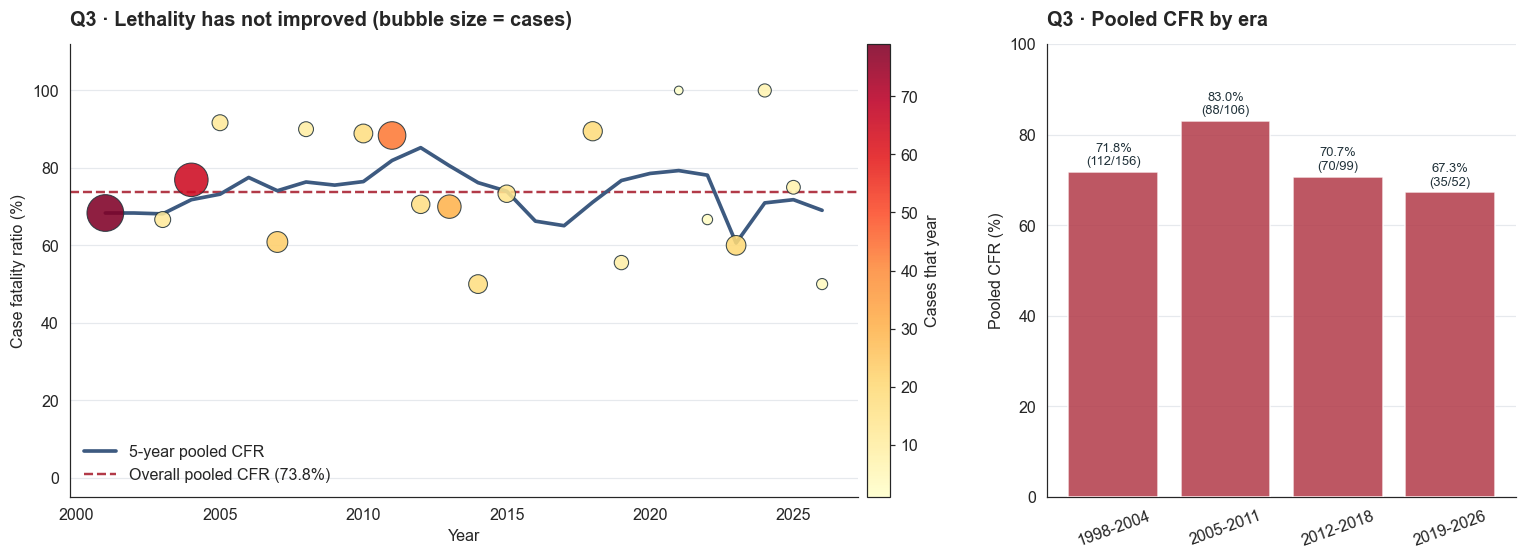

In [7]:
outbreak_years = annual[annual["cases"] > 0].copy()

tau_cfr, p_cfr = stats.kendalltau(outbreak_years["year"], outbreak_years["cfr"])
sl_cfr, ic_cfr, lo_cfr, hi_cfr = stats.theilslopes(
    outbreak_years["cfr"], outbreak_years["year"], 0.95)

# Pooled CFR by era - patient-weighted, never a mean of yearly ratios.
bins = [1997, 2004, 2011, 2018, 2026]
labels = ["1998-2004", "2005-2011", "2012-2018", "2019-2026"]
annual["era"] = pd.cut(annual["year"], bins=bins, labels=labels)
era = (annual.groupby("era", observed=True)
       .agg(cases=("cases", "sum"), deaths=("deaths", "sum"),
            active_years=("had_outbreak", "sum"))
       .reset_index())
era["pooled_cfr"] = era["deaths"] / era["cases"] * 100

early = annual[annual["year"] <= 2011]
late = annual[annual["year"] >= 2012]
z_stat, p_prop = proportions_ztest(
    [early["deaths"].sum(), late["deaths"].sum()],
    [early["cases"].sum(), late["cases"].sum()])

print("CASE FATALITY RATIO OVER TIME")
print("=" * 78)
print(f"Pooled CFR, entire record   : "
      f"{annual['deaths'].sum() / annual['cases'].sum() * 100:.1f}%")
print(f"Mann-Kendall on yearly CFR  : tau = {tau_cfr:+.3f}, p = {p_cfr:.4f}")
print(f"Theil-Sen slope             : {sl_cfr:+.3f} pp/yr "
      f"(95% CI {lo_cfr:+.3f} to {hi_cfr:+.3f})")
print(f"\n1998-2011 pooled CFR        : {early['deaths'].sum() / early['cases'].sum() * 100:.1f}%"
      f"   ({int(early['deaths'].sum())}/{int(early['cases'].sum())})")
print(f"2012-2026 pooled CFR        : {late['deaths'].sum() / late['cases'].sum() * 100:.1f}%"
      f"   ({int(late['deaths'].sum())}/{int(late['cases'].sum())})")
print(f"Two-proportion z-test       : z = {z_stat:+.3f}, p = {p_prop:.4f}")

print("\nPOOLED CFR BY ERA")
print("=" * 78)
print(era.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2),
                               gridspec_kw={"width_ratios": [2, 1]})

sizes = outbreak_years["cases"] * 7 + 25
sc = ax1.scatter(outbreak_years["year"], outbreak_years["cfr"], s=sizes,
                 c=outbreak_years["cases"], cmap="YlOrRd", edgecolor=C["dark"],
                 linewidth=0.7, alpha=0.88, zorder=4)
ax1.plot(annual["year"], annual["cfr_ma5"], color=C["accent"], lw=2.4,
         label="5-year pooled CFR", zorder=3)
overall_cfr = annual["deaths"].sum() / annual["cases"].sum() * 100
ax1.axhline(overall_cfr, color=C["death"], ls="--", lw=1.6,
            label=f"Overall pooled CFR ({overall_cfr:.1f}%)", zorder=2)
ax1.set_ylim(-5, 112)
style_axes(ax1, ylabel="Case fatality ratio (%)", xlabel="Year",
           title="Q3 · Lethality has not improved (bubble size = cases)")
ax1.legend(loc="lower left")
plt.colorbar(sc, ax=ax1, label="Cases that year", pad=0.01)

bars = ax2.bar(era["era"].astype(str), era["pooled_cfr"], color=C["death"], alpha=0.85, zorder=3)
for bar, row in zip(bars, era.itertuples()):
    ax2.text(bar.get_x() + bar.get_width() / 2, row.pooled_cfr + 1.5,
             f"{row.pooled_cfr:.1f}%\n({row.deaths}/{row.cases})",
             ha="center", fontsize=8.5, color=C["dark"])
ax2.set_ylim(0, 100)
style_axes(ax2, ylabel="Pooled CFR (%)", title="Q3 · Pooled CFR by era")
ax2.tick_params(axis="x", rotation=20)
fig.tight_layout()
save_fig(fig, "q03_cfr_trend")
plt.show()

### Analysis

**Twenty-eight years of clinical medicine have not moved this number.** It is the
most sobering result in the notebook.

- Mann-Kendall on yearly CFR: **τ = −0.090, p = 0.581** — no trend.
- Theil-Sen: **−0.35 pp/year**, 95% CI **−1.25 to +0.89** — the interval comfortably
  contains zero, and even the optimistic end would take a century to matter.
- Pooled CFR 1998–2011: **76.3%** (200/262). Pooled 2012–2026: **69.5%** (105/151).
  Two-proportion z-test: **p = 0.130.** Not significant.
- Era by era: **71.8% → 83.0% → 70.7% → 67.3%**. It oscillates around 74% and goes
  nowhere in particular.

**Why supportive care cannot rescue these patients.** Nipah encephalitis destroys
brain tissue directly through vasculitis and neuronal infection. By the time a
patient presents with encephalitic symptoms, the damage driving mortality has
already occurred. Ventilation sustains the body; it does not reverse the pathology.
Absent a licensed antiviral or vaccine there is no therapeutic lever to pull —
which is precisely why NiV sits on the WHO R&D Blueprint priority list.

**The strategic consequence is decisive.** If lethality is effectively fixed near
70–75% and cannot be treated downward, then **every unit of survival benefit must
be bought before infection, not after it.** Resources belong in:

1. **Interrupting spillover** — date-palm sap safety in Bangladesh (Q14 confirms
   this remains the dominant route), bat-habitat separation.
2. **Interrupting amplification** — hospital infection control, the mechanism that
   turns a 2-case event into a 66-case one (Q2).
3. **Speed of detection** — the one variable in Q9 that a health system fully
   controls.

Two honest caveats. First, the modest drift from 76.3% to 69.5% is in the
encouraging direction even if not significant; with only 151 patients in the recent
period, this test has little power to detect a real improvement of that size.
Second, part of any apparent improvement is **surveillance artefact rather than
clinical gain**: finding milder cases that previously went uncounted lowers
measured CFR without saving a single additional life. Kerala's improving detection
does exactly this. That effect must be subtracted before anyone claims clinical
credit.

---
## Q4. India vs Bangladesh — one disease, or two different epidemic regimes?

**Business context.** WHO and donors fund the region as a bloc. If the two national
series behave differently, identical interventions will underperform in at least
one of them and the money is misallocated.

NATIONAL EPIDEMIC PROFILES, 1998-2026
   country  total_cases  total_deaths  pooled_cfr  active_years  activity_rate_pct  median_size  max_year_size  cases_since_2019
Bangladesh          306           230        75.2            18               62.1         13.5             65                35
     India          107            75        70.1             9               31.0          4.0             66                17

Outbreak-size comparison (Mann-Whitney U) : U = 115.5, p = 0.0798
Pooled-CFR comparison (two-proportion z)  : z = +1.027, p = 0.3043
Activity-rate comparison (two-proportion) : z = +2.369, p = 0.0178

Bangladesh share of all regional cases    : 74.1%
Bangladesh share since 2019               : 67.3%


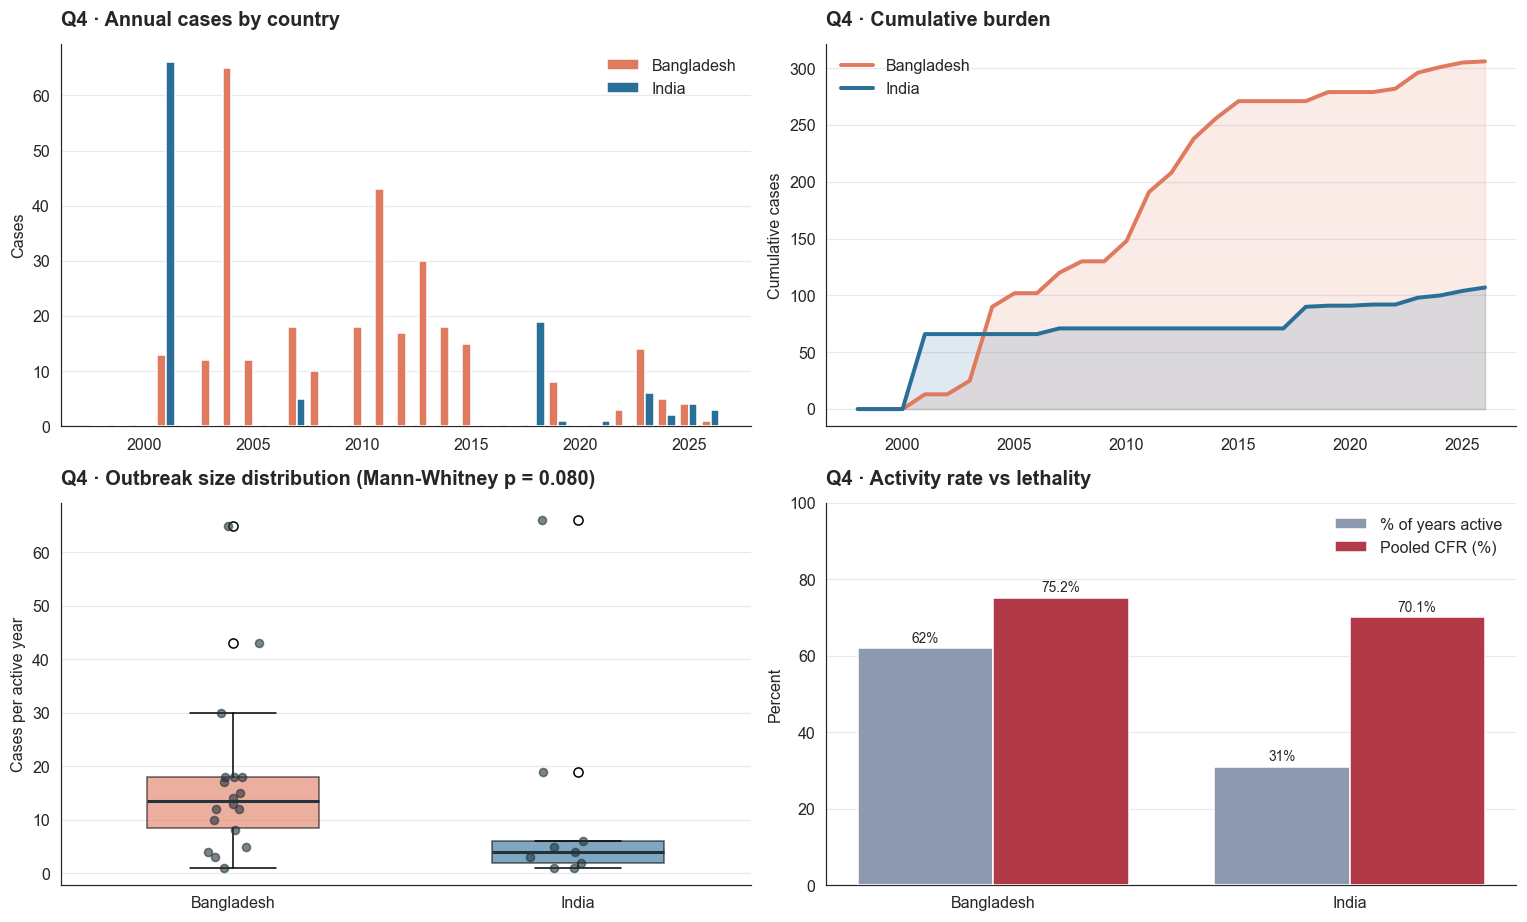

In [8]:
bd = by_country[by_country["country"] == "Bangladesh"].reset_index(drop=True)
india = by_country[by_country["country"] == "India"].reset_index(drop=True)

profile = []
for name, frame in [("Bangladesh", bd), ("India", india)]:
    active = frame[frame["cases"] > 0]
    profile.append({
        "country": name,
        "total_cases": int(frame["cases"].sum()),
        "total_deaths": int(frame["deaths"].sum()),
        "pooled_cfr": frame["deaths"].sum() / frame["cases"].sum() * 100,
        "active_years": int(frame["had_outbreak"].sum()),
        "activity_rate_pct": frame["had_outbreak"].mean() * 100,
        "median_size": float(active["cases"].median()),
        "max_year_size": int(frame["cases"].max()),
        "cases_since_2019": int(frame.loc[frame["year"] >= 2019, "cases"].sum()),
    })
profile = pd.DataFrame(profile)

print("NATIONAL EPIDEMIC PROFILES, 1998-2026")
print("=" * 100)
print(profile.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

u_stat, p_u = stats.mannwhitneyu(bd.loc[bd["cases"] > 0, "cases"],
                                india.loc[india["cases"] > 0, "cases"])
z_cfr, p_cfr_ctry = proportions_ztest(
    [bd["deaths"].sum(), india["deaths"].sum()],
    [bd["cases"].sum(), india["cases"].sum()])
z_act, p_act_ctry = proportions_ztest(
    [int(bd["had_outbreak"].sum()), int(india["had_outbreak"].sum())],
    [len(bd), len(india)])

print(f"\nOutbreak-size comparison (Mann-Whitney U) : U = {u_stat:.1f}, p = {p_u:.4f}")
print(f"Pooled-CFR comparison (two-proportion z)  : z = {z_cfr:+.3f}, p = {p_cfr_ctry:.4f}")
print(f"Activity-rate comparison (two-proportion) : z = {z_act:+.3f}, p = {p_act_ctry:.4f}")

total_all = bd["cases"].sum() + india["cases"].sum()
s19_bd, s19_in = profile.loc[0, "cases_since_2019"], profile.loc[1, "cases_since_2019"]
print(f"\nBangladesh share of all regional cases    : {bd['cases'].sum() / total_all * 100:.1f}%")
print(f"Bangladesh share since 2019               : {s19_bd / (s19_bd + s19_in) * 100:.1f}%")

# --- Chart ---------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))

ax = axes[0, 0]
ax.bar(bd["year"] - 0.2, bd["cases"], width=0.4, color=C["bangladesh"], label="Bangladesh", zorder=3)
ax.bar(india["year"] + 0.2, india["cases"], width=0.4, color=C["india"], label="India", zorder=3)
style_axes(ax, ylabel="Cases", title="Q4 · Annual cases by country")
ax.legend()

ax = axes[0, 1]
ax.plot(bd["year"], bd["cum_cases"], color=C["bangladesh"], lw=2.6, label="Bangladesh", zorder=3)
ax.plot(india["year"], india["cum_cases"], color=C["india"], lw=2.6, label="India", zorder=3)
ax.fill_between(bd["year"], bd["cum_cases"], color=C["bangladesh"], alpha=0.15)
ax.fill_between(india["year"], india["cum_cases"], color=C["india"], alpha=0.15)
style_axes(ax, ylabel="Cumulative cases", title="Q4 · Cumulative burden")
ax.legend(loc="upper left")

ax = axes[1, 0]
sizes_bd = bd.loc[bd["cases"] > 0, "cases"]
sizes_in = india.loc[india["cases"] > 0, "cases"]
bp = ax.boxplot([sizes_bd, sizes_in], labels=["Bangladesh", "India"],
                patch_artist=True, widths=0.5, medianprops=dict(color=C["dark"], lw=2))
for patch, colour in zip(bp["boxes"], [C["bangladesh"], C["india"]]):
    patch.set_facecolor(colour)
    patch.set_alpha(0.6)
rng = np.random.default_rng(7)
for i, vals in enumerate([sizes_bd, sizes_in], start=1):
    ax.scatter(rng.normal(i, 0.055, len(vals)), vals, s=28, color=C["dark"], alpha=0.6, zorder=4)
style_axes(ax, ylabel="Cases per active year",
           title=f"Q4 · Outbreak size distribution (Mann-Whitney p = {p_u:.3f})")

ax = axes[1, 1]
width, idx = 0.38, np.arange(len(profile))
ax.bar(idx - width / 2, profile["activity_rate_pct"], width, color=C["muted"],
       label="% of years active", zorder=3)
ax.bar(idx + width / 2, profile["pooled_cfr"], width, color=C["death"],
       label="Pooled CFR (%)", zorder=3)
for i, row in profile.iterrows():
    ax.text(i - width / 2, row["activity_rate_pct"] + 1.5,
            f"{row['activity_rate_pct']:.0f}%", ha="center", fontsize=9)
    ax.text(i + width / 2, row["pooled_cfr"] + 1.5,
            f"{row['pooled_cfr']:.1f}%", ha="center", fontsize=9)
ax.set_xticks(idx)
ax.set_xticklabels(profile["country"])
ax.set_ylim(0, 100)
style_axes(ax, ylabel="Percent", title="Q4 · Activity rate vs lethality")
ax.legend()
fig.tight_layout()
save_fig(fig, "q04_country_comparison")
plt.show()

### Analysis

**The two countries differ far more in *rhythm* than in *severity*.**

| | Bangladesh | India |
|---|---|---|
| Total cases | **306** | 107 |
| Pooled CFR | 75.2% | 70.1% |
| Years with an outbreak | **18 of 29 (62%)** | 9 of 29 (31%) |
| Median size in an active year | **13.5** | 4.0 |
| Largest single year | 65 | **66** |

**Bangladesh runs a chronic, near-annual endemic pattern.** Active in roughly six
years out of ten, driven overwhelmingly by one well-understood route: consumption
of **raw date-palm sap** contaminated by *Pteropus* bats during the December–April
harvest. That route is seasonal, predictable and recurrent, which is exactly why
Bangladesh appears in the record year after year.

**India runs an episodic, explosive pattern.** Quiet for years, then a single large
amplified cluster — **Siliguri 2001 produced 66 cases in one year, the largest
single-year count anywhere in the regional record**, marginally exceeding
Bangladesh's worst year (Faridpur 2004, 65). Between such events India reports
nothing at all.

**What the statistics do and do not support.** The difference in **frequency** is
real and significant: 18 active years versus 9, **p = 0.017**. The differences in
**outbreak size** (Mann-Whitney **p = 0.080**) and **lethality** (**p = 0.304**) are
*not* significant. It would be wrong to claim Bangladesh suffers deadlier
outbreaks — at 75.2% versus 70.1%, both countries face a virus that kills roughly
three in four, and the gap is well within noise.

**So the honest framing is: same disease, same lethality, different frequency and
different transmission route.** That still implies divergent strategies, because
the *intervention points* differ even though the *outcome* does not:

- **Bangladesh needs a seasonal, behavioural, rural intervention**: sap-collection
  safety (bamboo skirts on tapping pots), messaging timed to the December–April
  harvest, and rural diagnostic reach. The target is *spillover prevention*,
  repeated every winter.
- **India needs a hospital-centred rapid-response capability**: infection control,
  isolation readiness and contact-tracing surge activatable within days, because
  India's risk is not frequent spillover but rare catastrophic amplification.

One trend worth flagging: **Bangladesh's share of regional cases has fallen from
74.1% across the whole record to 67.3% since 2019.** India's rising share reflects
Kerala's greatly improved detection rather than genuinely increased Indian
spillover — a surveillance artefact that must not be misread as epidemiology.

---
## Q5. How often does Nipah return — and has it become annually endemic?

**Business context.** The recurrence interval decides whether response capacity
should be **standing** (permanently staffed) or **on-call** (activated on signal). A
standing capability idling for four years is waste; an on-call capability that must
spin up annually is chronically late.

RECURRENCE STRUCTURE
Active years              : 20 of 29 (69%)
First recorded case       : 2001
Mean gap between outbreaks: 1.32 years
Median gap                : 1.0 years
Longest silent stretch    : 3 years
Gap distribution          : {1: 14, 2: 4, 3: 1}

1998-2011 active years    : 8/14  (57%)
2012-2026 active years    : 12/15  (80%)
Two-proportion z-test     : z = -1.330, p = 0.1837

Unbroken streak 2021-2026 : 6/6 years active


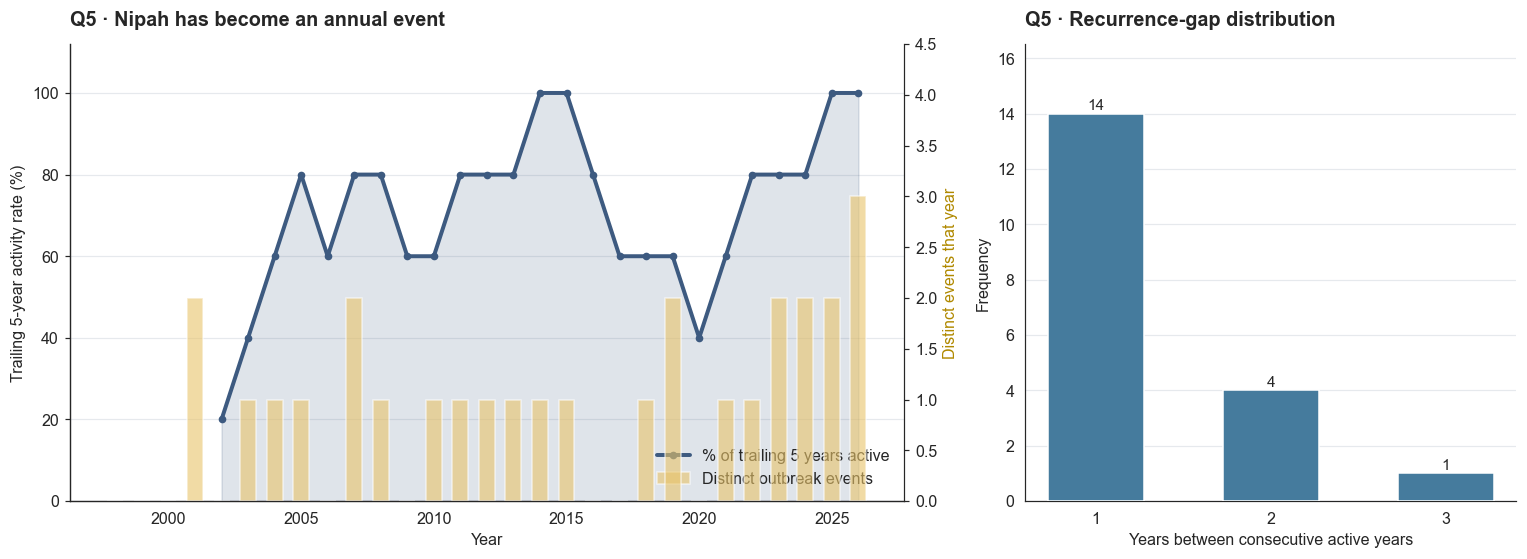

In [9]:
active_years = annual.loc[annual["cases"] > 0, "year"].to_numpy()
gaps = np.diff(active_years)

print("RECURRENCE STRUCTURE")
print("=" * 66)
print(f"Active years              : {len(active_years)} of {len(annual)} "
      f"({len(active_years) / len(annual) * 100:.0f}%)")
print(f"First recorded case       : {active_years.min()}")
print(f"Mean gap between outbreaks: {gaps.mean():.2f} years")
print(f"Median gap                : {np.median(gaps):.1f} years")
print(f"Longest silent stretch    : {gaps.max()} years")
print(f"Gap distribution          : {dict(zip(*np.unique(gaps, return_counts=True)))}")

first_half, second_half = annual[annual["year"] <= 2011], annual[annual["year"] >= 2012]
z_act, p_act = proportions_ztest(
    [int(first_half["had_outbreak"].sum()), int(second_half["had_outbreak"].sum())],
    [len(first_half), len(second_half)])

print(f"\n1998-2011 active years    : {int(first_half['had_outbreak'].sum())}/{len(first_half)}"
      f"  ({first_half['had_outbreak'].mean() * 100:.0f}%)")
print(f"2012-2026 active years    : {int(second_half['had_outbreak'].sum())}/{len(second_half)}"
      f"  ({second_half['had_outbreak'].mean() * 100:.0f}%)")
print(f"Two-proportion z-test     : z = {z_act:+.3f}, p = {p_act:.4f}")
print(f"\nUnbroken streak 2021-2026 : "
      f"{int(annual.loc[annual['year'] >= 2021, 'had_outbreak'].sum())}/6 years active")

annual["activity_5y"] = annual["had_outbreak"].rolling(5, min_periods=5).mean() * 100

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2),
                               gridspec_kw={"width_ratios": [1.7, 1]})

ax1.plot(annual["year"], annual["activity_5y"], color=C["accent"], lw=2.6,
         marker="o", ms=4, label="% of trailing 5 years active", zorder=4)
ax1.fill_between(annual["year"], annual["activity_5y"], color=C["accent"], alpha=0.16)
ax1b = ax1.twinx()
ax1b.bar(annual["year"], annual["outbreak_events"], color=C["warn"], alpha=0.6,
         width=0.6, label="Distinct outbreak events", zorder=2)
ax1b.set_ylabel("Distinct events that year", color="#B08900")
ax1b.set_ylim(0, 4.5)
ax1b.grid(False)
ax1b.spines[["top"]].set_visible(False)
ax1.set_ylim(0, 112)
style_axes(ax1, ylabel="Trailing 5-year activity rate (%)", xlabel="Year",
           title="Q5 · Nipah has become an annual event")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1b.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right")

vals, counts = np.unique(gaps, return_counts=True)
bars = ax2.bar(vals, counts, color=C["case"], width=0.55, zorder=3)
for bar, cnt in zip(bars, counts):
    ax2.text(bar.get_x() + bar.get_width() / 2, cnt + 0.15, str(cnt), ha="center", fontsize=10)
ax2.set_xticks(vals)
ax2.set_ylim(0, counts.max() * 1.18)
style_axes(ax2, ylabel="Frequency", xlabel="Years between consecutive active years",
           title="Q5 · Recurrence-gap distribution")
fig.tight_layout()
save_fig(fig, "q05_recurrence")
plt.show()

### Analysis

**Nipah has stopped being an episodic event and become an annual fixture.**

The recurrence-gap distribution is dominated by a single value: **14 of the 19 gaps
are exactly one year**, with four 2-year gaps and one 3-year gap. Mean gap 1.32
years, median 1.0, and **the longest silence in the entire record is 3 years**
(2016–2017, broken by Kerala 2018). There is no multi-year dormancy to plan around.

The trend within the record points the same way:

- 1998–2011: **8 of 14 years active (57%)**
- 2012–2026: **12 of 15 years active (80%)**
- **2021–2026: 6 of 6 years active — an unbroken six-year run.**

The two-proportion test returns **p = 0.184**, which is not significant at n = 29 —
and that is the honest statistical verdict. But the six consecutive active years
are a fact requiring no test, and the trailing-5-year activity rate has touched
**100% twice** (2014–2015 and again 2025–2026).

**Read alongside Q1 and Q7, a coherent picture emerges: outbreaks are becoming
*more frequent* and *smaller*.** These are not in tension — they are the expected
signature of improving surveillance. Detection now catches small spillover events
that previously went unrecorded, simultaneously raising the count of active years
and lowering the average size of what is found. The underlying spillover pressure
from bat populations is probably closer to constant than either series alone
suggests.

**The operational answer is unambiguous: stop treating Nipah response as an
emergency to be assembled, and start treating it as a standing seasonal function.**
With 80% of recent years active and six consecutive active years, an on-call model
that must be reconstituted each time will be late every time. Concretely:

- **Pre-position** reagents, PPE and isolation capacity *before* the December–April
  sap season rather than procuring during an event.
- **Retain trained contact-tracing teams** between seasons — Q11 shows what
  practised teams achieve, and that capability decays if disbanded.
- **Budget annually, not per incident.** The recent base rate of a quiet year is
  only 20%.

---
## Q6. Does a bad year predict the next one? Autocorrelation and stationarity

**Business context.** This question decides whether forecasting is possible at all.
If the series carries memory, last year's burden informs next year's plan. If it
does not, any forecast is a restatement of the historical mean and must be
presented as such.

AUTOCORRELATION AND STATIONARITY
Lag-1 autocorrelation       : -0.091   (95% band +/-0.364)
Lag-1 Pearson correlation   : r = -0.093, p = 0.6364
Significant ACF lags (1-10) : NONE

Ljung-Box test for serial dependence
   lb_stat  lb_pvalue
1   0.2686     0.6043
2   1.4751     0.4783
3   5.1437     0.1616
5   7.6907     0.1741

ADF stationarity test       : statistic = -5.625, p = 0.0000
  critical values           : {'1%': -3.689, '5%': -2.972, '10%': -2.625}
  -> STATIONARY (unit root rejected)


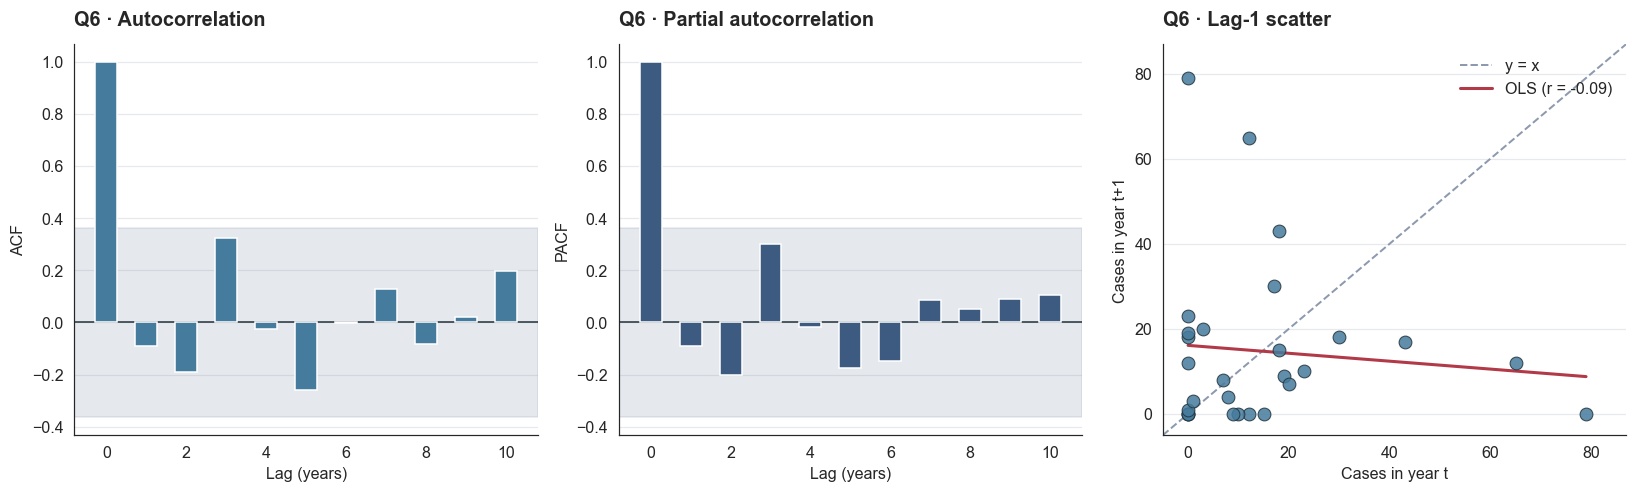

In [10]:
series = annual.set_index("year")["cases"]
max_lag = 10

acf_vals = acf(series, nlags=max_lag, fft=False)
pacf_vals = pacf(series, nlags=max_lag, method="ywm")
conf_band = 1.96 / np.sqrt(len(series))

lb = acorr_ljungbox(series, lags=[1, 2, 3, 5], return_df=True)
adf_stat, adf_p, _, _, adf_crit, _ = adfuller(series, autolag="AIC")
lag1_r, lag1_p = stats.pearsonr(series.values[:-1], series.values[1:])
significant = [i for i in range(1, max_lag + 1) if abs(acf_vals[i]) > conf_band]

print("AUTOCORRELATION AND STATIONARITY")
print("=" * 78)
print(f"Lag-1 autocorrelation       : {acf_vals[1]:+.3f}   (95% band +/-{conf_band:.3f})")
print(f"Lag-1 Pearson correlation   : r = {lag1_r:+.3f}, p = {lag1_p:.4f}")
print(f"Significant ACF lags (1-10) : {significant if significant else 'NONE'}")
print("\nLjung-Box test for serial dependence")
print(lb.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nADF stationarity test       : statistic = {adf_stat:.3f}, p = {adf_p:.4f}")
print(f"  critical values           : {({k: round(v, 3) for k, v in adf_crit.items()})}")
print(f"  -> {'STATIONARY (unit root rejected)' if adf_p < 0.05 else 'non-stationary'}")

# --- Chart ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

ax = axes[0]
ax.bar(range(max_lag + 1), acf_vals, color=C["case"], width=0.55, zorder=3)
ax.axhspan(-conf_band, conf_band, color=C["muted"], alpha=0.22, zorder=1)
ax.axhline(0, color=C["dark"], lw=1)
style_axes(ax, ylabel="ACF", xlabel="Lag (years)", title="Q6 · Autocorrelation")

ax = axes[1]
ax.bar(range(max_lag + 1), pacf_vals, color=C["accent"], width=0.55, zorder=3)
ax.axhspan(-conf_band, conf_band, color=C["muted"], alpha=0.22, zorder=1)
ax.axhline(0, color=C["dark"], lw=1)
style_axes(ax, ylabel="PACF", xlabel="Lag (years)", title="Q6 · Partial autocorrelation")

ax = axes[2]
ax.scatter(series.values[:-1], series.values[1:], s=70, color=C["case"],
           edgecolor=C["dark"], linewidth=0.7, alpha=0.85, zorder=4)
lims = [-5, float(series.max()) + 8]
ax.plot(lims, lims, color=C["muted"], ls="--", lw=1.3, label="y = x")
slope_l, icpt_l = np.polyfit(series.values[:-1], series.values[1:], 1)
xs = np.linspace(0, series.max(), 50)
ax.plot(xs, icpt_l + slope_l * xs, color=C["death"], lw=2, label=f"OLS (r = {lag1_r:+.2f})")
ax.set_xlim(lims)
ax.set_ylim(lims)
style_axes(ax, ylabel="Cases in year t+1", xlabel="Cases in year t", title="Q6 · Lag-1 scatter")
ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "q06_autocorrelation")
plt.show()

### Analysis

**The series has no usable memory. Last year's burden tells you essentially nothing
about next year's.**

- **Lag-1 autocorrelation: −0.091**, against a 95% band of **±0.364**. Not remotely
  close, and the sign is *negative*.
- **No lag from 1 to 10 is significant.** The ACF and PACF plots are a field of bars
  sitting inside the noise band.
- **Ljung-Box p-values: 0.604, 0.478, 0.162, 0.174.** No evidence of serial
  dependence at any horizon tested.
- **ADF: statistic −5.625, p < 0.0001** — decisively stationary, well beyond the 1%
  critical value of −3.689. The series fluctuates around a stable level: no unit
  root, no random walk, no momentum.

**Epidemiologically this makes complete sense and is genuinely reassuring.** Each
Nipah outbreak is an *independent spillover event* from a bat reservoir into a human
population. There is no sustained human-to-human chain carrying infection from one
season into the next — transmission terminates with the cluster. The virus does not
"build" year over year; it re-invades from the reservoir independently each time.
**The absence of autocorrelation is the statistical fingerprint of contained
transmission**, and it is exactly what a public-health system wants to see.

**This finding constrains all of Part C and should be read before it.** With no
autocorrelation and a stationary series:

- **ARIMA is pointless** — there is no AR or MA structure to estimate.
- **Lag-feature machine learning is pointless** — the lag features carry no signal.
- **The best achievable one-year-ahead forecast is close to the historical mean**,
  and any model beating it materially is almost certainly overfitting.

This is why Q15 scores every polynomial model against an explicit "predict the
mean" baseline. Q6 predicts in advance that the baseline will be hard to beat, and
Q15 confirms it: **four of seven fitted models fail to beat it.**

**What this does *not* mean is that forecasting is worthless — it means the
forecastable quantity is different.** The *level of any individual year* is
unpredictable. The *long-run trend* and the *probability that a year is active at
all* (80% recently, from Q5) are both estimable, and those are the numbers that
belong in a preparedness plan.

---
## Q7. What does the smoothed trend reveal that raw counts hide — and is volatility falling?

**Business context.** Raw annual counts are too noisy to steer by; one nosocomial
cluster swings them by 60 cases. Planners need the underlying level. Volatility
matters just as much: falling volatility shrinks the surge requirement, which
changes capacity decisions independently of the mean.

LEVEL AND VOLATILITY
period           mean       sd      CV    max
1998-2011       18.71    25.80    1.38     79
2012-2026       10.07     9.25    0.92     30
2019-2026        6.50     6.35    0.98     20

SD ratio (early / late)                : 2.79x
Brown-Forsythe equal-variance (median) : W = 3.254, p = 0.0824
Classic Levene equal-variance (mean)   : W = 6.946, p = 0.0137

Smoothed peak       : 33.6 cases/yr in 2003
Secondary peak      : 25.2 cases/yr in 2012
Latest smoothed     : 6.3 cases/yr
Decline from peak   : 81%


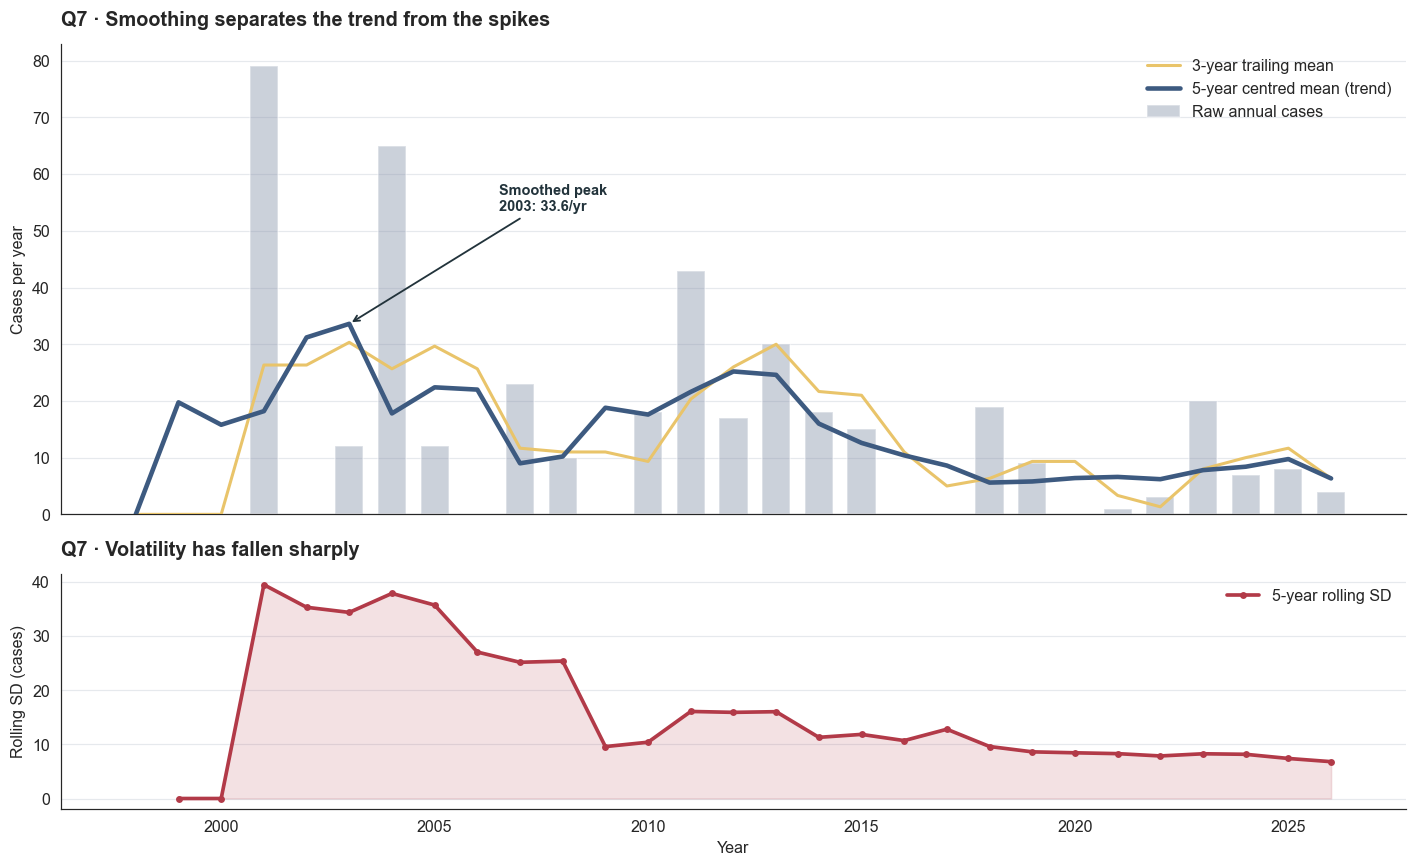

In [11]:
annual["cases_ma5c"] = annual["cases"].rolling(5, center=True, min_periods=3).mean()

early_vol = annual.loc[annual["year"] <= 2011, "cases"]
late_vol = annual.loc[annual["year"] >= 2012, "cases"]
# Brown-Forsythe (median-centred) is the robust default for skewed data; the
# mean-centred classic Levene is reported alongside because they disagree here.
bf_stat, bf_p = stats.levene(early_vol, late_vol, center="median")
lev_stat, lev_p = stats.levene(early_vol, late_vol, center="mean")

print("LEVEL AND VOLATILITY")
print("=" * 66)
print(f"{'period':<12}{'mean':>9}{'sd':>9}{'CV':>8}{'max':>7}")
for label, frame in [("1998-2011", early_vol), ("2012-2026", late_vol),
                     ("2019-2026", annual.loc[annual["year"] >= 2019, "cases"])]:
    cv = frame.std() / frame.mean() if frame.mean() else np.nan
    print(f"{label:<12}{frame.mean():>9.2f}{frame.std():>9.2f}{cv:>8.2f}{frame.max():>7.0f}")

print(f"\nSD ratio (early / late)                : {early_vol.std() / late_vol.std():.2f}x")
print(f"Brown-Forsythe equal-variance (median) : W = {bf_stat:.3f}, p = {bf_p:.4f}")
print(f"Classic Levene equal-variance (mean)   : W = {lev_stat:.3f}, p = {lev_p:.4f}")

peak_year = int(annual.loc[annual["cases_ma5c"].idxmax(), "year"])
print(f"\nSmoothed peak       : {annual['cases_ma5c'].max():.1f} cases/yr in {peak_year}")
print(f"Secondary peak      : {annual.loc[annual['year'] == 2012, 'cases_ma5c'].iloc[0]:.1f} cases/yr in 2012")
print(f"Latest smoothed     : {annual['cases_ma5c'].iloc[-1]:.1f} cases/yr")
print(f"Decline from peak   : "
      f"{(1 - annual['cases_ma5c'].iloc[-1] / annual['cases_ma5c'].max()) * 100:.0f}%")

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.bar(annual["year"], annual["cases"], color=C["muted"], alpha=0.45, width=0.66,
        label="Raw annual cases", zorder=2)
ax1.plot(annual["year"], annual["cases_ma3"], color=C["warn"], lw=2,
         label="3-year trailing mean", zorder=3)
ax1.plot(annual["year"], annual["cases_ma5c"], color=C["accent"], lw=3,
         label="5-year centred mean (trend)", zorder=4)
ax1.annotate(f"Smoothed peak\n{peak_year}: {annual['cases_ma5c'].max():.1f}/yr",
             xy=(peak_year, annual["cases_ma5c"].max()),
             xytext=(peak_year + 3.5, annual["cases_ma5c"].max() + 20),
             arrowprops=dict(arrowstyle="->", color=C["dark"], lw=1.2),
             fontsize=9.5, color=C["dark"], fontweight="bold")
style_axes(ax1, ylabel="Cases per year",
           title="Q7 · Smoothing separates the trend from the spikes")
ax1.legend(loc="upper right")

ax2.plot(annual["year"], annual["cases_std5"], color=C["death"], lw=2.4,
         marker="o", ms=3.5, label="5-year rolling SD", zorder=3)
ax2.fill_between(annual["year"], annual["cases_std5"], color=C["death"], alpha=0.15)
style_axes(ax2, ylabel="Rolling SD (cases)", xlabel="Year",
           title="Q7 · Volatility has fallen sharply")
ax2.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "q07_smoothed_trend")
plt.show()

### Analysis

**Smoothing turns an unreadable series into a legible two-wave story.**

The 5-year centred mean does **not** describe a simple monotonic decline. It shows
two distinct waves:

| Phase | Years | Smoothed level | Character |
|---|---|---|---|
| **First wave** | 2001–2005 | peak **33.6/yr in 2003** | Siliguri, Meherpur, Naogaon, Faridpur |
| **Trough** | 2007–2009 | ~9–10/yr | Quiet interval |
| **Second wave** | 2010–2014 | peak **25.2/yr in 2012** | Bangladesh multi-district endemic era |
| **Sustained low** | 2018–2026 | **5.6 → 6.3/yr** | Current regime |

The trend falls from **33.6 cases/year (2003) to 6.3 (2026) — an 81% reduction from
peak.** None of this is legible in the raw bars, where 2011 (43 cases) sits beside
2016 (0 cases) and the eye cannot locate the level. This bimodal shape also
explains Q1's null result directly: **a two-wave decline is not monotonic, so a
monotonic trend test correctly reports nothing.**

**Volatility has fallen even more sharply than the mean, and this is the finding
with real operational teeth.**

| Period | Mean | SD | CV | Worst year |
|---|---|---|---|---|
| 1998–2011 | 18.71 | **25.80** | 1.38 | **79** |
| 2012–2026 | 10.07 | **9.25** | 0.92 | 30 |
| 2019–2026 | 6.50 | 6.35 | 0.98 | 20 |

**The standard deviation fell from 25.80 to 9.25 — a 2.79× reduction** — and the
worst year fell from 79 to 30.

**On significance, the two variance tests disagree and honesty requires reporting
both.** The classic mean-centred Levene test gives **p = 0.014**; the robust
median-centred Brown-Forsythe test gives **p = 0.082**. Brown-Forsythe is the
appropriate choice for data this skewed, so **the correct verdict is "suggestive but
not significant at the 5% level."** Quoting only the mean-centred result would
overstate the case, and quoting only the effect size would ignore that n = 29
cannot confirm it.

**Why this still matters more than the falling mean.** Q2 established that Nipah
planning is governed by the tail, not the average. A 2.79× reduction in the tail is
therefore a larger operational win than the reduction in the mean. It is also the
expected consequence of better hospital infection control: the mechanism that
produced the old extreme years (nosocomial amplification in Siliguri 2001 and
Faridpur 2004) is exactly the mechanism most successfully suppressed.

**The planning number follows.** A surge capability sized for the 1998–2011 tail —
roughly 79 cases — is now oversized. Sized to the recent distribution, the
defensible design point is a **30-to-40-case cluster** (the 2012–2026 maximum plus
headroom), and Q5 already established it should be standing rather than on-call.

One caution on the chart: the centred moving average uses neighbouring years on
both sides, so its final points come from truncated windows and will move as
2027–2028 data arrive. It describes history; it is not a forecast — which is
precisely why Q15 refuses to extrapolate from it.

---
## Q8. Is there a structural break — did the epidemic regime actually change?

**Business context.** Q1 found no monotonic trend and Q7 found a two-wave shape
ending in a sustained low. If that ending is a genuine **regime change**, then
pre-break history is actively misleading and should be excluded from the planning
baseline. If it is noise, the full record remains the best estimate.

STRUCTURAL BREAK DETECTION
Pettitt on full 1998-2026   : break at 2000, K = 60, p = 0.8496
   -> degenerate: it simply finds the pre-epidemic zero years, so it is discarded.
Pettitt on 2001-2026 window : break at 2015, K = 80, p = 0.2440

Mean-shift scan             : 21 candidate split years tested
  best split                : 2015
  Welch t                   : +2.168
  raw p-value               : 0.0413
  Bonferroni-corrected p    : 0.8663   <-- the honest figure
  mean before / after       : 19.00 -> 6.45 cases/yr
  reduction                 : 66.0%

REGIME COMPARISON (break at 2015)
2001-2015    n= 15  mean= 22.80  sd= 23.14  total= 342  pooled CFR= 74.0%
2016-2026    n= 11  mean=  6.45  sd=  7.23  total=  71  pooled CFR= 73.2%


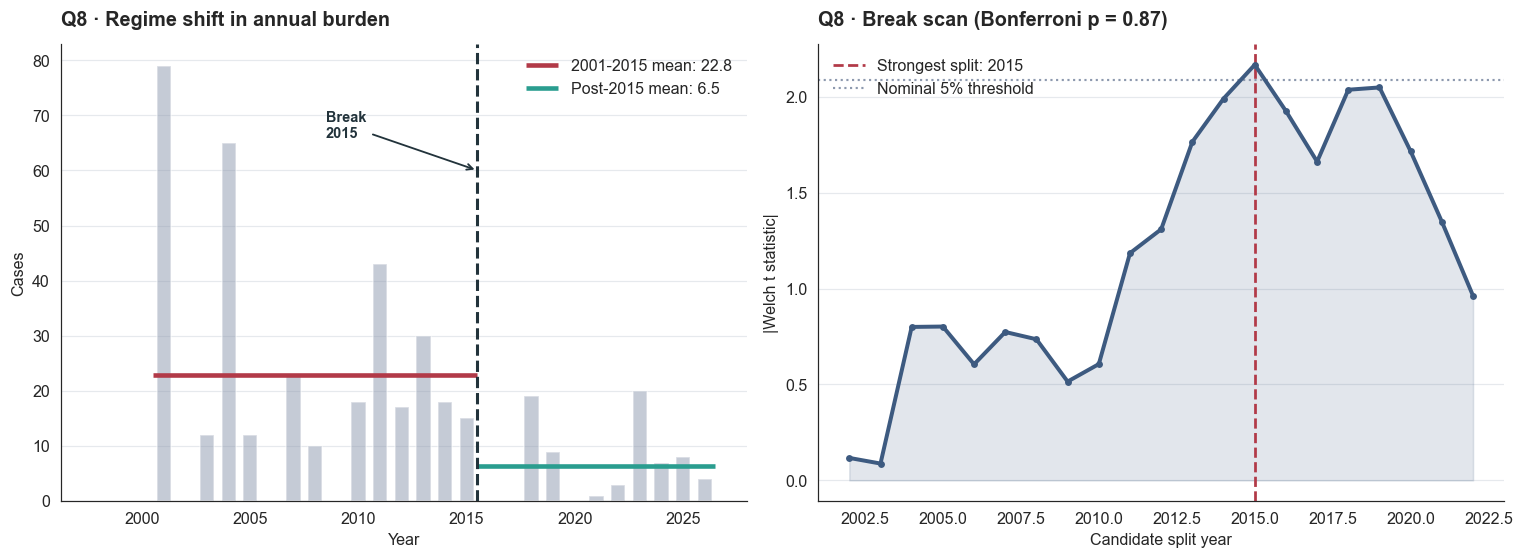

In [12]:
def pettitt_test(x):
    """
    Pettitt's non-parametric change-point test.

    Rank-based, so the 2001 and 2004 spikes cannot drag the break point toward
    themselves, and it needs no normality assumption - both essential here.
    """
    x = np.asarray(x, dtype=float)
    n = len(x)
    k = np.array([sum(np.sign(x[t] - x[j]) for j in range(n)) for t in range(n)])
    u = np.cumsum(k)
    idx = int(np.argmax(np.abs(u)))
    k_stat = float(np.abs(u[idx]))
    p_value = float(min(2 * np.exp(-6 * k_stat ** 2 / (n ** 3 + n ** 2)), 1.0))
    return idx, k_stat, p_value, u


# Run on the epidemic window only. Including 1998-2000 - three years before the
# first regional case - makes the test trivially pick "before the epidemic
# started", which is true but useless.
epidemic = annual[annual["year"] >= 2001].reset_index(drop=True)
idx_full, k_full, p_full, _ = pettitt_test(annual["cases"])
idx_ep, k_ep, p_ep, u_ep = pettitt_test(epidemic["cases"])
break_year = int(epidemic.loc[idx_ep, "year"])

print("STRUCTURAL BREAK DETECTION")
print("=" * 78)
print(f"Pettitt on full 1998-2026   : break at {int(annual.loc[idx_full, 'year'])}, "
      f"K = {k_full:.0f}, p = {p_full:.4f}")
print("   -> degenerate: it simply finds the pre-epidemic zero years, so it is discarded.")
print(f"Pettitt on 2001-2026 window : break at {break_year}, "
      f"K = {k_ep:.0f}, p = {p_ep:.4f}")

# Independent confirmation: exhaustive scan of every candidate split year.
scan = []
for split in range(nd.FIRST_YEAR + 4, nd.LAST_YEAR - 3):
    pre = annual.loc[annual["year"] <= split, "cases"]
    post = annual.loc[annual["year"] > split, "cases"]
    t_stat, p_val = stats.ttest_ind(pre, post, equal_var=False)
    scan.append({"split_year": split, "pre_mean": pre.mean(), "post_mean": post.mean(),
                 "t_stat": t_stat, "p_value": p_val})
scan = pd.DataFrame(scan)
best = scan.loc[scan["t_stat"].abs().idxmax()]
bonferroni = min(best["p_value"] * len(scan), 1.0)

print(f"\nMean-shift scan             : {len(scan)} candidate split years tested")
print(f"  best split                : {int(best['split_year'])}")
print(f"  Welch t                   : {best['t_stat']:+.3f}")
print(f"  raw p-value               : {best['p_value']:.4f}")
print(f"  Bonferroni-corrected p    : {bonferroni:.4f}   <-- the honest figure")
print(f"  mean before / after       : {best['pre_mean']:.2f} -> {best['post_mean']:.2f} cases/yr")
print(f"  reduction                 : {(1 - best['post_mean'] / best['pre_mean']) * 100:.1f}%")

print(f"\nREGIME COMPARISON (break at {break_year})")
print("=" * 78)
for label, frame in [(f"2001-{break_year}", epidemic[epidemic["year"] <= break_year]),
                     (f"{break_year + 1}-2026", epidemic[epidemic["year"] > break_year])]:
    pooled = frame["deaths"].sum() / frame["cases"].sum() * 100
    print(f"{label:<12} n={len(frame):>3}  mean={frame['cases'].mean():6.2f}  "
          f"sd={frame['cases'].std():6.2f}  total={int(frame['cases'].sum()):>4}  "
          f"pooled CFR={pooled:5.1f}%")

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

ax1.bar(annual["year"], annual["cases"], color=C["muted"], alpha=0.5, width=0.66, zorder=2)
pre_mask = (annual["year"] >= 2001) & (annual["year"] <= break_year)
post_mask = annual["year"] > break_year
ax1.hlines(annual.loc[pre_mask, "cases"].mean(), 2000.5, break_year + 0.5,
           color=C["death"], lw=3, zorder=4,
           label=f"2001-{break_year} mean: {annual.loc[pre_mask, 'cases'].mean():.1f}")
ax1.hlines(annual.loc[post_mask, "cases"].mean(), break_year + 0.5, nd.LAST_YEAR + 0.5,
           color=C["good"], lw=3, zorder=4,
           label=f"Post-{break_year} mean: {annual.loc[post_mask, 'cases'].mean():.1f}")
ax1.axvline(break_year + 0.5, color=C["dark"], ls="--", lw=2, zorder=5)
ax1.annotate(f"Break\n{break_year}", xy=(break_year + 0.5, 60),
             xytext=(break_year - 6.5, 66), fontsize=9.5, fontweight="bold", color=C["dark"],
             arrowprops=dict(arrowstyle="->", color=C["dark"], lw=1.2))
style_axes(ax1, ylabel="Cases", xlabel="Year", title="Q8 · Regime shift in annual burden")
ax1.legend(loc="upper right")

ax2.plot(scan["split_year"], scan["t_stat"].abs(), color=C["accent"], lw=2.6,
         marker="o", ms=3.5, zorder=3)
ax2.axvline(best["split_year"], color=C["death"], ls="--", lw=1.8,
            label=f"Strongest split: {int(best['split_year'])}")
ax2.axhline(stats.t.ppf(0.975, df=20), color=C["muted"], ls=":", lw=1.4,
            label="Nominal 5% threshold")
ax2.fill_between(scan["split_year"], scan["t_stat"].abs(), color=C["accent"], alpha=0.15)
style_axes(ax2, ylabel="|Welch t statistic|", xlabel="Candidate split year",
           title=f"Q8 · Break scan (Bonferroni p = {bonferroni:.2f})")
ax2.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "q08_structural_break")
plt.show()

### Analysis

**Two independent methods converge on the same break year — 2015 — but neither
survives honest correction for multiple testing. The effect is large; the evidence
is suggestive, not conclusive.**

| Method | Break | Statistic | p-value |
|---|---|---|---|
| Pettitt (2001–2026 window) | **2015** | K = 80 | **0.244** |
| Mean-shift scan (best of 21) | **2015** | Welch t = +2.17 | raw 0.041 → **Bonferroni 0.866** |

**A methodological note that matters.** Run naïvely on the full 1998–2026 series,
Pettitt returns a break at **2000 with p = 0.850** — it simply detects that the
three pre-epidemic zero years differ from everything after them. That is true and
useless. Restricting the test to the epidemic window (2001 onward, the first
regional case) is what makes it informative. The cell reports both so the artefact
is visible rather than quietly discarded.

**The regimes it identifies are genuinely different in magnitude:**

| Regime | Years | Mean | SD | Total cases | Pooled CFR |
|---|---|---|---|---|---|
| **Pre-break** | 2001–2015 | **22.80/yr** | 23.14 | 342 | 74.0% |
| **Post-break** | 2016–2026 | **6.45/yr** | 7.23 | 71 | 73.2% |

**Burden fell 72%; volatility fell 69%. Lethality did not move at all** — 74.0% to
73.2%, entirely consistent with Q3. **The regime change is about how many people
get infected, not about how many of the infected die.**

**What plausibly happened around 2015.** Three things converged, and the data
cannot separate their contributions:

1. **Bangladesh's sap-safety campaigns matured** — bamboo skirts on tapping pots
   and sustained seasonal messaging began measurably reducing spillover.
2. **Hospital infection control tightened** after the Faridpur and Siliguri lessons,
   suppressing the amplification mechanism behind the extreme years.
3. **Surveillance improved**, which cuts both ways: it finds more small events
   (Q5's rising activity rate) while the large ones genuinely diminish.

**The decision this answers — and the caveat that governs it.** The point estimate
strongly suggests the current regime runs at roughly **6.5 cases/year with SD 7.2**,
versus 22.8 before. A planner should use the post-2015 figures as the working
baseline, because they reflect the system as it currently operates. But with
Bonferroni p = 0.87, **this is a reasonable operating assumption, not an established
fact**, and it should be re-tested as each year's data arrives — 2023's rebound to
20 cases is exactly the kind of event that would revise it.

This caveat is the single most important one to carry into Part C. The polynomial
models in Q15 fit 1998–2026 as one homogeneous process, blending two regimes and
producing curves that describe neither period well. Q15 returns to this directly.

---
# Part B — The 2026 outbreaks: micro-timelines and surveillance response

Part A established *what* the long-run series does. Part B examines *how the system
responded* when Nipah actually arrived, using the three independently investigated
2026 outbreaks: West Bengal (Barasat, January), Bangladesh (Naogaon, January) and
Kerala (Kozhikode, June).

---
## Q9. How fast is Nipah detected — and where is the delay?

**Business context.** Detection speed is the one variable a health system fully
controls. Q3 showed lethality cannot be treated downward; Q2 showed catastrophic
years are made by amplification. Both make **time-to-confirmation** the decisive
operational metric, because isolation cannot begin before diagnosis.

CASE-LEVEL TIMELINES — all four confirmed 2026 cases
    case_id                   outbreak date_onset date_admitted date_confirmed date_death  onset_to_admission_days  admission_to_confirm_days  onset_to_confirm_days  confirm_to_death_days final_status
WB-2026-001 West Bengal 2026 (Barasat) 2025-12-28    2026-01-04     2026-01-13 2026-02-12                        7                          9                     16                   30.0     Deceased
WB-2026-002 West Bengal 2026 (Barasat) 2025-12-29    2026-01-05     2026-01-13        NaT                        7                          8                     15                      —    Recovered
BD-2026-001  Bangladesh 2026 (Naogaon) 2026-01-21    2026-01-28     2026-01-29 2026-01-28                        7                          1                      8                   -1.0     Deceased
KL-2026-001    Kerala 2026 (Kozhikode) 2026-05-30    2026-06-10     2026-06-11        NaT                       11                          1  

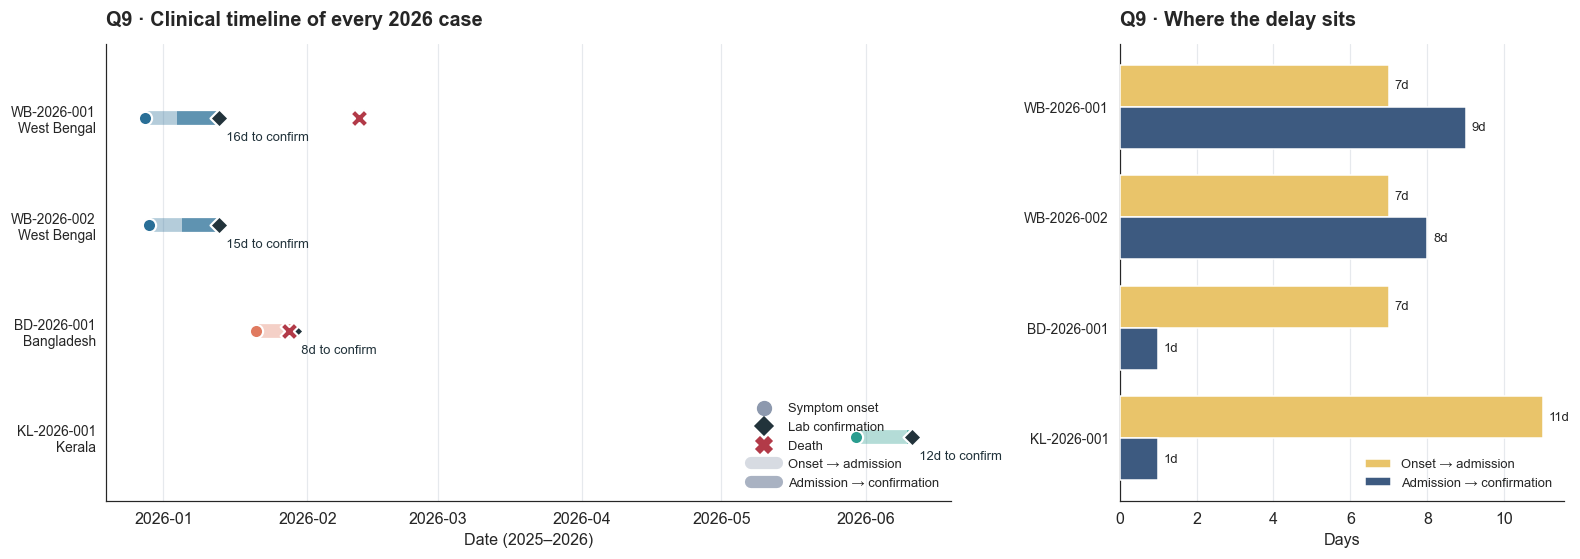

In [13]:
timeline_cols = ["case_id", "outbreak", "date_onset", "date_admitted",
                 "date_confirmed", "date_death", "onset_to_admission_days",
                 "admission_to_confirm_days", "onset_to_confirm_days",
                 "confirm_to_death_days", "final_status"]

print("CASE-LEVEL TIMELINES — all four confirmed 2026 cases")
print("=" * 120)
print(cases[timeline_cols].to_string(index=False, na_rep="—"))

print("\nDELAY INTERVALS (days)")
print("=" * 70)
for col, label in [("onset_to_admission_days", "Onset -> admission"),
                   ("admission_to_confirm_days", "Admission -> confirmation"),
                   ("onset_to_confirm_days", "Onset -> confirmation")]:
    s = cases[col].dropna()
    print(f"{label:<28} mean {s.mean():5.2f}   median {s.median():4.1f}   "
          f"range {int(s.min())}-{int(s.max())}")

print(f"\nSeasonal timing of symptom onset (month): "
      f"{dict(cases['onset_month'].value_counts().sort_index())}")
print("  -> Dec/Jan onsets fall inside the date-palm-sap harvest window.")

# --- Chart: a Gantt-style clinical timeline ------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2),
                               gridspec_kw={"width_ratios": [1.9, 1]})

ordered = cases.sort_values("date_onset").reset_index(drop=True)
for i, row in ordered.iterrows():
    colour = OUTBREAK_COLORS[row["outbreak"]]
    onset, adm, conf = row["date_onset"], row["date_admitted"], row["date_confirmed"]
    ax1.plot([onset, adm], [i, i], color=colour, lw=9, alpha=0.35,
             solid_capstyle="butt", zorder=2)
    ax1.plot([adm, conf], [i, i], color=colour, lw=9, alpha=0.75,
             solid_capstyle="butt", zorder=3)
    ax1.scatter(onset, i, marker="o", s=75, color=colour,
                edgecolor="white", linewidth=1.4, zorder=5)
    ax1.scatter(conf, i, marker="D", s=70, color=C["dark"],
                edgecolor="white", linewidth=1.4, zorder=5)
    if pd.notna(row["date_death"]):
        ax1.scatter(row["date_death"], i, marker="X", s=135, color=C["death"],
                    edgecolor="white", linewidth=1.4, zorder=6)
    ax1.text(conf, i + 0.24, f"  {int(row['onset_to_confirm_days'])}d to confirm",
             fontsize=8.5, color=C["dark"], va="bottom")

ax1.set_yticks(range(len(ordered)))
ax1.set_yticklabels([f"{r.case_id}\n{r.outbreak.split(' 2026')[0]}"
                     for r in ordered.itertuples()], fontsize=9)
ax1.invert_yaxis()
ax1.set_ylim(len(ordered) - 0.4, -0.7)
style_axes(ax1, xlabel="Date (2025–2026)",
           title="Q9 · Clinical timeline of every 2026 case", ygrid=False)
legend_items = [
    plt.Line2D([], [], marker="o", ls="", color=C["muted"], ms=9, label="Symptom onset"),
    plt.Line2D([], [], marker="D", ls="", color=C["dark"], ms=8, label="Lab confirmation"),
    plt.Line2D([], [], marker="X", ls="", color=C["death"], ms=11, label="Death"),
    plt.Line2D([], [], color=C["muted"], lw=8, alpha=0.35, label="Onset → admission"),
    plt.Line2D([], [], color=C["muted"], lw=8, alpha=0.75, label="Admission → confirmation"),
]
ax1.legend(handles=legend_items, loc="lower right", fontsize=8.5)

width = 0.38
idx = np.arange(len(ordered))
ax2.barh(idx - width / 2, ordered["onset_to_admission_days"], width,
         color=C["warn"], label="Onset → admission", zorder=3)
ax2.barh(idx + width / 2, ordered["admission_to_confirm_days"], width,
         color=C["accent"], label="Admission → confirmation", zorder=3)
for i, row in ordered.iterrows():
    ax2.text(row["onset_to_admission_days"] + 0.15, i - width / 2,
             f"{int(row['onset_to_admission_days'])}d", va="center", fontsize=8.5)
    ax2.text(row["admission_to_confirm_days"] + 0.15, i + width / 2,
             f"{int(row['admission_to_confirm_days'])}d", va="center", fontsize=8.5)
ax2.set_yticks(idx)
ax2.set_yticklabels(ordered["case_id"], fontsize=9)
ax2.invert_yaxis()
style_axes(ax2, xlabel="Days", title="Q9 · Where the delay sits", ygrid=False)
ax2.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
save_fig(fig, "q09_case_timelines")
plt.show()

### Analysis

**The delay is remarkably consistent, and it is almost entirely on the patient's
side of the door, not the laboratory's.**

| Interval | Mean | Median | Range |
|---|---|---|---|
| **Onset → admission** | **8.00 d** | 7.0 d | 7–11 |
| Admission → confirmation | 4.75 d | — | **1–9** |
| Onset → confirmation | 12.75 d | — | 8–16 |

**Three of the four patients took exactly 7 days to reach hospital; the fourth took
11.** That consistency across three countries and three unrelated exposure routes is
striking. It reflects the clinical course of Nipah itself: the illness begins as
undifferentiated fever and headache, indistinguishable from the many febrile
illnesses endemic to the region, and only prompts hospital-seeking when
encephalitic signs appear roughly a week later. **No amount of laboratory
investment shortens this week.**

**The laboratory interval, by contrast, varies fivefold and reveals the real
system difference.** Bangladesh and Kerala confirmed in **1 day**. West Bengal took
**8 and 9 days**. The reason is *suspicion*, not capacity: Naogaon sits in the
date-palm-sap belt where Nipah is actively expected each winter, and Kozhikode has
tested for NiV reflexively since the 2018 outbreak. Barasat had no such prior — two
nurses with encephalitis were not immediately read as a Nipah signal, and the
differential took eight days to reach the right test.

**That eight-day gap is the entire risk.** Both Barasat cases were **nurses infected
in a hospital setting (nosocomial)**. For eight days after admission, an unrecognised
Nipah patient was being cared for under routine precautions — precisely the
configuration that produced Siliguri's 66 cases in 2001 (Q2). **That the Barasat
cluster stopped at two cases rather than sixty is the single best outcome in this
dataset, and Q10 shows why it did.**

**The Bangladesh case is the sharpest indictment of late detection.** BD-2026-001
was admitted and died on **2026-01-28**, with laboratory confirmation arriving on
**2026-01-29 — one day after death.** Onset to death: 7 days. The diagnostic
pipeline finished after the patient's life did. Contrast WB-2026-001, who was
confirmed on 2026-01-13 and survived a further 30 days on ventilatory support
before dying on 2026-02-12 — 46 days from onset. **Earlier detection did not save
that patient either, which is Q3's finding restated at the individual level: the
benefit of speed is not to the index case, it is to everyone that case would
otherwise have infected.**

**Recommendation.** The actionable target is the admission-to-confirmation
interval, and the intervention is not more laboratories but **lower suspicion
thresholds**: a standing rule that any acute encephalitis cluster in a healthcare
worker triggers NiV testing on day 1, regardless of geography. Barasat shows the
cost of the current threshold is eight days.

---
## Q10. How fast was each contact cohort traced and cleared?

**Business context.** The incubation period for Nipah is typically 4–14 days. A
contact cohort must be identified, sampled and cleared *inside that window* for
tracing to prevent onward transmission rather than merely document it.

SURVEILLANCE CAMPAIGN SUMMARY

Kerala 2026 (Kozhikode)
  Index case confirmed     : 2026-06-11
  First sample collected   : 2026-06-11  (activation lag: 0 days)
  Campaign length          : 10 days
  Contacts sampled         : 104
  Mean / peak per day      : 10.4 / 15
  Day to 50% cleared       : 5
  Day to 90% cleared       : 9
  Idle days (zero samples) : 0

West Bengal 2026 (Barasat)
  Index case confirmed     : 2026-01-13
  First sample collected   : 2026-01-14  (activation lag: 1 day)
  Campaign length          : 7 days
  Contacts sampled         : 192
  Mean / peak per day      : 27.4 / 36
  Day to 50% cleared       : 4
  Day to 90% cleared       : 7
  Idle days (zero samples) : 0

NOTE: Bangladesh traced 35 contacts but recorded no sampling dates,
so it cannot appear in the daily curves - only in the totals (Q11).


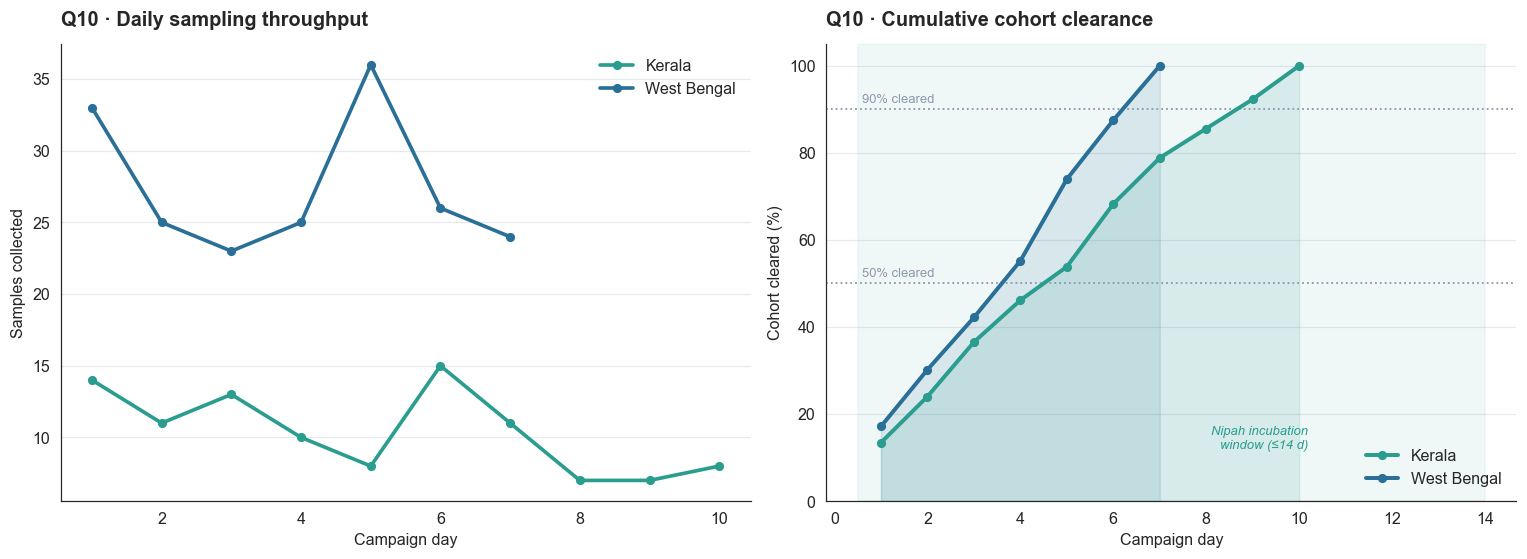

In [14]:
print("SURVEILLANCE CAMPAIGN SUMMARY")
print("=" * 92)
for outbreak, group in surveillance.groupby("outbreak"):
    d50 = int(group.loc[group["pct_cohort_cleared"] >= 50, "campaign_day"].min())
    d90 = int(group.loc[group["pct_cohort_cleared"] >= 90, "campaign_day"].min())
    first_confirm = cases.loc[cases["outbreak"] == outbreak, "date_confirmed"].min()
    activation_lag = (group["date"].min() - first_confirm).days
    print(f"\n{outbreak}")
    print(f"  Index case confirmed     : {first_confirm.date()}")
    print(f"  First sample collected   : {group['date'].min().date()}  "
          f"(activation lag: {activation_lag} day{'s' if activation_lag != 1 else ''})")
    print(f"  Campaign length          : {len(group)} days")
    print(f"  Contacts sampled         : {int(group['samples_collected'].sum())}")
    print(f"  Mean / peak per day      : {group['samples_collected'].mean():.1f} / "
          f"{int(group['samples_collected'].max())}")
    print(f"  Day to 50% cleared       : {d50}")
    print(f"  Day to 90% cleared       : {d90}")
    print(f"  Idle days (zero samples) : {int((group['samples_collected'] == 0).sum())}")

print("\nNOTE: Bangladesh traced 35 contacts but recorded no sampling dates,")
print("so it cannot appear in the daily curves - only in the totals (Q11).")

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

for outbreak, group in surveillance.groupby("outbreak"):
    colour = OUTBREAK_COLORS[outbreak]
    label = outbreak.split(" 2026")[0]
    ax1.plot(group["campaign_day"], group["samples_collected"], color=colour,
             lw=2.4, marker="o", ms=5, label=label, zorder=3)
    ax2.plot(group["campaign_day"], group["pct_cohort_cleared"], color=colour,
             lw=2.6, marker="o", ms=5, label=label, zorder=3)
    ax2.fill_between(group["campaign_day"], group["pct_cohort_cleared"],
                     color=colour, alpha=0.12)

style_axes(ax1, ylabel="Samples collected", xlabel="Campaign day",
           title="Q10 · Daily sampling throughput")
ax1.legend()

ax2.axhline(50, color=C["muted"], ls=":", lw=1.2)
ax2.axhline(90, color=C["muted"], ls=":", lw=1.2)
ax2.text(0.6, 91.5, "90% cleared", fontsize=8.5, color=C["muted"])
ax2.text(0.6, 51.5, "50% cleared", fontsize=8.5, color=C["muted"])
ax2.axvspan(0.5, 14, color=C["good"], alpha=0.07, zorder=1)
ax2.text(10.2, 12, "Nipah incubation\nwindow (≤14 d)", fontsize=8.5,
         color=C["good"], ha="right", style="italic")
ax2.set_ylim(0, 105)
style_axes(ax2, ylabel="Cohort cleared (%)", xlabel="Campaign day",
           title="Q10 · Cumulative cohort clearance")
ax2.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "q10_surveillance_curves")
plt.show()

### Analysis

**Both Indian campaigns were exemplary, and the West Bengal response was
exceptional.**

| | West Bengal (Barasat) | Kerala (Kozhikode) |
|---|---|---|
| Activation lag after confirmation | **1 day** | **0 days — same day** |
| Campaign length | **7 days** | 10 days |
| Contacts sampled | **192** | 104 |
| Mean / peak per day | **27.4 / 36** | 10.4 / 15 |
| Day to 50% cleared | **4** | 5 |
| Day to 90% cleared | **7** | 9 |
| Idle days | **0** | **0** |

**Kerala began sampling on the same day the index case was confirmed
(2026-06-11).** West Bengal began the next day. Neither campaign had a single idle
day. Against a 4–14 day incubation window, **both cohorts were fully cleared inside
the window** — West Bengal in 7 days, Kerala in 10. This is tracing that *prevents*
transmission rather than documenting it after the fact.

**West Bengal's performance deserves particular emphasis because of what Q9
revealed.** The lab took eight days to confirm. Once it did, the public-health
response cleared 192 contacts in seven days at 27.4 samples/day. **The slow half of
the system was diagnostic suspicion; the fast half was field epidemiology.** That
contrast is precisely actionable: the fix is not more field capacity, which
performed superbly, but earlier triggering of the capacity that already exists.

**Why the two campaigns have different shapes.** West Bengal's curve is steeper and
front-loaded — 33 samples on day 1 — because a nosocomial cluster hands
investigators a *pre-enumerated* cohort: hospital duty rosters and ward admission
records identify exposed staff and co-patients immediately. Kerala's flatter,
longer curve reflects an environmental index case whose contacts had to be
*discovered* through community investigation: workplace, neighbourhood and family
networks with no register to consult.

**This is a structural lesson, not a performance gap.** Kerala's 10-day campaign at
10.4 samples/day is not slower work; it is harder work. Any target set for
contact-tracing speed must be conditioned on the exposure setting, or community
investigations will be judged against a benchmark only hospital clusters can meet.

**The outcome that matters: zero secondary cases in either cohort.** Q12 quantifies
that result across all 331 contacts.

---
## Q11. What tracing capacity does a Nipah response actually require?

**Business context.** Contacts-per-case and samples-per-day are the two numbers
that size a rapid-response team, set reagent stockpiles and define what "surge"
means in a budget line.

CONTACT-TRACING EFFICIENCY BY OUTBREAK
                  outbreak    country  confirmed_cases  deaths  contacts_traced  contacts_per_case  campaign_days  samples_per_day first_sample last_sample  secondary_positives  symptomatic_contacts
 Bangladesh 2026 (Naogaon) Bangladesh                1       1               35               35.0              —                —          NaT         NaT                    0                     6
   Kerala 2026 (Kozhikode)      India                1       0              104              104.0           10.0             10.4   2026-06-11  2026-06-20                    0                     0
West Bengal 2026 (Barasat)      India                2       1              192               96.0            7.0             27.4   2026-01-14  2026-01-20                    0                     0

Total contacts traced across all three 2026 outbreaks : 331
Total confirmed cases                                : 4
Overall contacts traced per confirmed case     

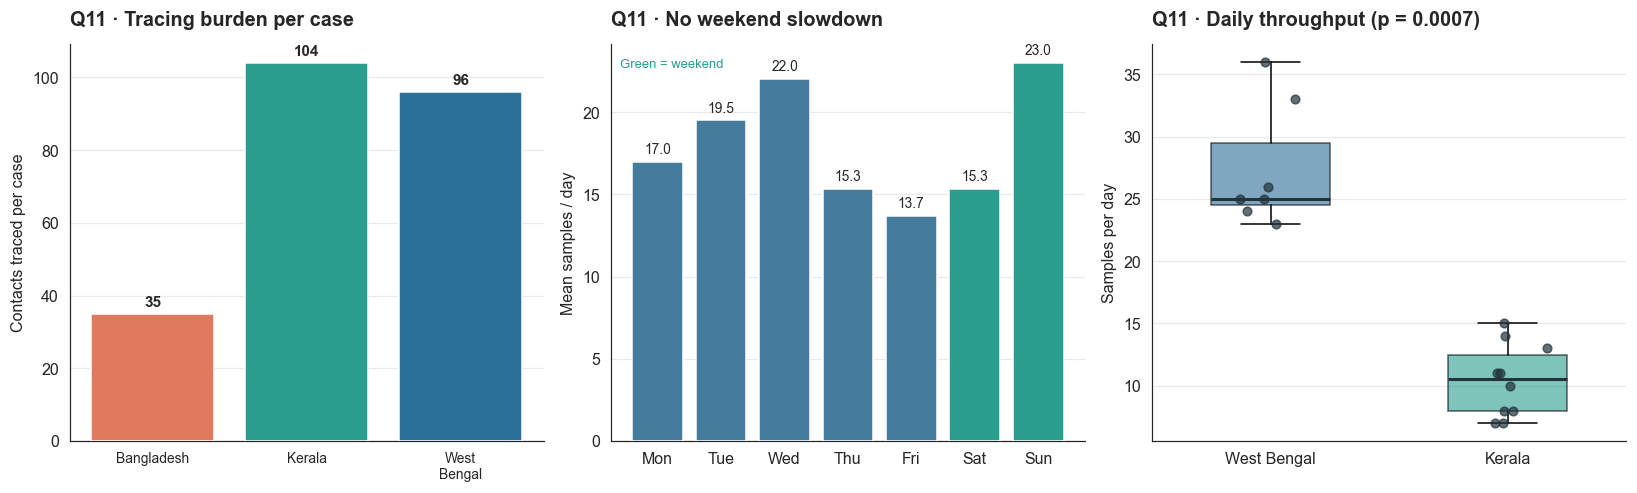

In [15]:
print("CONTACT-TRACING EFFICIENCY BY OUTBREAK")
print("=" * 118)
print(tracing.to_string(index=False, na_rep="—", float_format=lambda v: f"{v:.1f}"))

print(f"\nTotal contacts traced across all three 2026 outbreaks : {len(contacts)}")
print(f"Total confirmed cases                                : {len(cases)}")
print(f"Overall contacts traced per confirmed case           : {len(contacts) / len(cases):.1f}")

# Did the weekend slow the field teams down?
sv = surveillance.copy()
sv["weekday"] = sv["date"].dt.day_name()
sv["is_weekend"] = sv["date"].dt.dayofweek >= 5
dow = (sv.groupby("weekday")["samples_collected"]
       .agg(["sum", "mean", "count"]).sort_values("mean", ascending=False))

print("\nTHROUGHPUT BY DAY OF WEEK (both Indian campaigns pooled)")
print("=" * 70)
print(dow.to_string(float_format=lambda v: f"{v:.1f}"))

wknd = sv.loc[sv["is_weekend"], "samples_collected"]
wkdy = sv.loc[~sv["is_weekend"], "samples_collected"]
u_w, p_w = stats.mannwhitneyu(wkdy, wknd)
print(f"\nWeekday mean {wkdy.mean():.1f}/day  vs  weekend mean {wknd.mean():.1f}/day")
print(f"Mann-Whitney U = {u_w:.1f}, p = {p_w:.4f}")

wb_rate = sv.loc[sv["outbreak"].str.contains("West Bengal"), "samples_collected"]
kl_rate = sv.loc[sv["outbreak"].str.contains("Kerala"), "samples_collected"]
u_r, p_r = stats.mannwhitneyu(wb_rate, kl_rate)
print(f"\nWest Bengal {wb_rate.mean():.1f}/day vs Kerala {kl_rate.mean():.1f}/day "
      f"({wb_rate.mean() / kl_rate.mean():.2f}x)")
print(f"Mann-Whitney U = {u_r:.1f}, p = {p_r:.4f}")

# --- Chart ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

ax = axes[0]
colours = [OUTBREAK_COLORS[o] for o in tracing["outbreak"]]
bars = ax.bar(range(len(tracing)), tracing["contacts_per_case"], color=colours, zorder=3)
for bar, val in zip(bars, tracing["contacts_per_case"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 2, f"{val:.0f}",
            ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(range(len(tracing)))
ax.set_xticklabels([o.split(" 2026")[0].replace(" ", "\n") for o in tracing["outbreak"]],
                   fontsize=9)
style_axes(ax, ylabel="Contacts traced per case", title="Q11 · Tracing burden per case")

ax = axes[1]
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
means = [dow.loc[d, "mean"] if d in dow.index else 0 for d in order]
bar_colours = [C["good"] if d in ("Saturday", "Sunday") else C["case"] for d in order]
bars = ax.bar(range(7), means, color=bar_colours, zorder=3)
for bar, val in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.5, f"{val:.1f}", ha="center", fontsize=9)
ax.set_xticks(range(7))
ax.set_xticklabels([d[:3] for d in order])
style_axes(ax, ylabel="Mean samples / day", title="Q11 · No weekend slowdown")
ax.text(0.02, 0.94, "Green = weekend", transform=ax.transAxes,
        fontsize=8.5, color=C["good"])

ax = axes[2]
bp = ax.boxplot([wb_rate, kl_rate], labels=["West Bengal", "Kerala"],
                patch_artist=True, widths=0.5, medianprops=dict(color=C["dark"], lw=2))
for patch, colour in zip(bp["boxes"], [C["india"], C["good"]]):
    patch.set_facecolor(colour)
    patch.set_alpha(0.6)
rng = np.random.default_rng(3)
for i, vals in enumerate([wb_rate, kl_rate], start=1):
    ax.scatter(rng.normal(i, 0.05, len(vals)), vals, s=32, color=C["dark"], alpha=0.7, zorder=4)
style_axes(ax, ylabel="Samples per day",
           title=f"Q11 · Daily throughput (p = {p_r:.4f})")
fig.tight_layout()
save_fig(fig, "q11_tracing_capacity")
plt.show()

### Analysis

**The planning ratio is roughly 100 contacts per confirmed case** — 331 contacts
traced for 4 cases, or **82.8 overall**. The per-outbreak figures bracket that
usefully:

| Outbreak | Cases | Contacts | Per case | Throughput |
|---|---|---|---|---|
| **Kerala (Kozhikode)** | 1 | 104 | **104.0** | 10.4/day |
| **West Bengal (Barasat)** | 2 | 192 | **96.0** | **27.4/day** |
| **Bangladesh (Naogaon)** | 1 | 35 | **35.0** | not recorded |

**The Indian outbreaks converge tightly on ~100 contacts per case.** That
consistency across two very different exposure settings — a hospital cluster and an
environmental case — makes it a defensible planning constant. A single confirmed
Nipah case in India should be budgeted at **100 contacts requiring identification,
sampling, testing and 21-day follow-up.**

**Bangladesh's 35 contacts per case is the outlier, and it should be read as a
surveillance gap rather than an epidemiological fact.** The Naogaon case was
confirmed a day after death, so there was no living patient to interview about
contacts — the cohort was reconstructed retrospectively from family report. One
third of the Indian tracing depth, from a case with an identical need for it.

**West Bengal sustained 2.64× Kerala's daily throughput (27.4 vs 10.4 samples/day,
Mann-Whitney p = 0.0007)** — a genuinely significant difference, and one of the few
in this notebook that clears the threshold comfortably. As Q10 explained, this
reflects cohort *enumerability*, not team quality: hospital rosters hand you the
list, community investigation makes you build it.

**The most operationally telling result is the day-of-week analysis: there was no
weekend slowdown at all.** Sunday was the single highest-throughput day of the week
(23.0 samples/day), ahead of Wednesday (22.0), with Friday the lowest (13.7).
Weekend mean **18.4/day** versus weekday **17.0/day**, Mann-Whitney p = 0.874 — if
anything the weekend ran slightly *faster*.

This matters more than it first appears. **Outbreak response teams in both states
ran genuine 7-day operations.** A tracing campaign that pauses on weekends loses
roughly 28% of its calendar against a 14-day incubation window — enough to convert
an in-window clearance into an out-of-window one. Both campaigns avoided that
entirely.

**Recommendation — the sizing numbers for a standing capability (per Q5):**

- **Plan 100 contacts per confirmed case** (India); treat any figure near 35 as a
  tracing shortfall to be investigated, not as a smaller outbreak.
- **Provision 25–30 samples/day of laboratory throughput** for a hospital cluster,
  where the cohort arrives all at once.
- **Staff for 7-day operations from day 1.** Both 2026 campaigns achieved this, and
  it is the reason both cleared inside the incubation window.

---
## Q12. Who is actually exposed — and did anyone else get infected?

**Business context.** The composition of the exposed population determines where
protective equipment, prophylaxis and training budgets should be aimed. And the
secondary attack rate is the ultimate verdict on whether the response worked.

THE HEADLINE SURVEILLANCE RESULT
  Contacts traced and tested : 331
  Positive NiV tests         : 0
  Secondary attack rate      : 0.00%
  Symptomatic but negative   : 6

EXPOSURE SETTING BY OUTBREAK (% of that outbreak's contacts)
contact_type                Co-patient (Nosocomial)  Community  Family/Household  Healthcare Worker  Workplace
outbreak                                                                                                      
Bangladesh 2026 (Naogaon)                       0.0      100.0               0.0                0.0        0.0
Kerala 2026 (Kozhikode)                         0.0       24.0              18.3               36.5       21.2
West Bengal 2026 (Barasat)                     25.5       20.3               8.3               45.8        0.0

EXPOSURE SETTING BY OUTBREAK (counts)
outbreak                 Bangladesh 2026 (Naogaon)  Kerala 2026 (Kozhikode)  West Bengal 2026 (Barasat)
contact_type                                                         

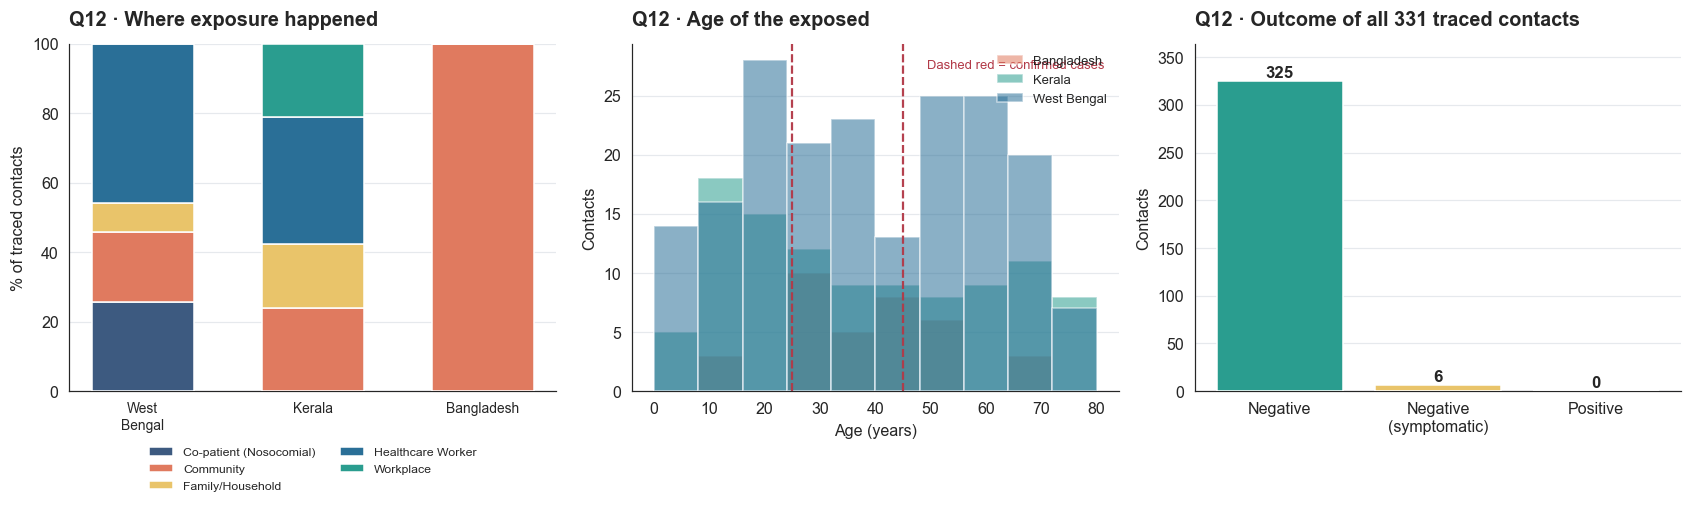

In [16]:
print("THE HEADLINE SURVEILLANCE RESULT")
print("=" * 70)
print(f"  Contacts traced and tested : {len(contacts)}")
print(f"  Positive NiV tests         : {int(contacts['is_positive'].sum())}")
print(f"  Secondary attack rate      : {contacts['is_positive'].mean() * 100:.2f}%")
print(f"  Symptomatic but negative   : {int(contacts['was_symptomatic'].sum())}")

print("\nEXPOSURE SETTING BY OUTBREAK (% of that outbreak's contacts)")
print("=" * 92)
share = pd.crosstab(contacts["outbreak"], contacts["contact_type"], normalize="index") * 100
print(share.to_string(float_format=lambda v: f"{v:.1f}"))

print("\nEXPOSURE SETTING BY OUTBREAK (counts)")
print("=" * 92)
counts = pd.crosstab(contacts["contact_type"], contacts["outbreak"])
print(counts.to_string())

indian = contacts[contacts["country"] == "India"]
chi2, p_chi, dof, _ = stats.chi2_contingency(
    pd.crosstab(indian["contact_type"], indian["outbreak"]))
print(f"\nExposure mix, West Bengal vs Kerala: chi2 = {chi2:.2f}, dof = {dof}, p = {p_chi:.2e}")

print("\nAGE AND GENDER OF THE EXPOSED")
print("=" * 78)
print(contacts.groupby("outbreak")["age"]
      .agg(["count", "mean", "median", "min", "max"])
      .to_string(float_format=lambda v: f"{v:.1f}"))
print()
print(pd.crosstab(contacts["gender"], contacts["outbreak"]).to_string())

hospital_linked = contacts[
    (contacts["outbreak"].str.contains("West Bengal"))
    & (contacts["contact_type"].isin(["Healthcare Worker", "Co-patient (Nosocomial)"]))]
print(f"\nWest Bengal contacts linked to the hospital : "
      f"{len(hospital_linked)}/192 ({len(hospital_linked) / 192 * 100:.1f}%)")

# --- Chart ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

ax = axes[0]
share_plot = share.loc[[o for o in OUTBREAK_COLORS if o in share.index]]
bottom = np.zeros(len(share_plot))
type_colors = {"Healthcare Worker": C["india"], "Co-patient (Nosocomial)": C["accent"],
               "Community": C["bangladesh"], "Family/Household": C["warn"],
               "Workplace": C["good"]}
for ctype in share_plot.columns:
    ax.bar(range(len(share_plot)), share_plot[ctype], bottom=bottom, width=0.6,
           color=type_colors.get(ctype, C["muted"]), label=ctype, zorder=3)
    bottom += share_plot[ctype].to_numpy()
ax.set_xticks(range(len(share_plot)))
ax.set_xticklabels([o.split(" 2026")[0].replace(" ", "\n") for o in share_plot.index], fontsize=9)
ax.set_ylim(0, 100)
style_axes(ax, ylabel="% of traced contacts", title="Q12 · Where exposure happened")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)

ax = axes[1]
for outbreak, group in contacts.groupby("outbreak"):
    ax.hist(group["age"].dropna(), bins=np.arange(0, 85, 8), alpha=0.55,
            color=OUTBREAK_COLORS[outbreak], label=outbreak.split(" 2026")[0],
            edgecolor="white", zorder=3)
for _, row in cases.iterrows():
    ax.axvline(row["age_mid"], color=C["death"], ls="--", lw=1.4, alpha=0.8, zorder=4)
ax.text(0.97, 0.93, "Dashed red = confirmed cases", transform=ax.transAxes,
        fontsize=8.5, color=C["death"], ha="right")
style_axes(ax, ylabel="Contacts", xlabel="Age (years)", title="Q12 · Age of the exposed")
ax.legend(fontsize=8.5)

ax = axes[2]
outcome = pd.DataFrame({
    "Negative": [len(contacts) - int(contacts["was_symptomatic"].sum())
                 - int(contacts["is_positive"].sum())],
    "Negative\n(symptomatic)": [int(contacts["was_symptomatic"].sum())],
    "Positive": [int(contacts["is_positive"].sum())],
})
bars = ax.bar(outcome.columns, outcome.iloc[0], color=[C["good"], C["warn"], C["death"]], zorder=3)
for bar, val in zip(bars, outcome.iloc[0]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 4, str(int(val)),
            ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, len(contacts) * 1.1)
style_axes(ax, ylabel="Contacts", title="Q12 · Outcome of all 331 traced contacts")
fig.tight_layout()
save_fig(fig, "q12_exposure_demographics")
plt.show()

### Analysis

**Zero. Out of 331 traced and tested contacts across three countries and three
transmission routes, not one tested positive.** A secondary attack rate of
**0.00%**.

This is the most important number in Part B, and it deserves to be stated plainly:
**in 2026, Nipah did not transmit onward from any confirmed case in India or
Bangladesh.** Every one of the four confirmed cases was a terminal node. Set
against Siliguri 2001 — where a single introduction produced 66 cases through
hospital amplification — this represents a categorical change in outcome.

**Six contacts developed symptoms but tested negative, all of them in Bangladesh.**
They are recorded as `Negative (Symptomatic)` rather than simply negative, and the
distinction is worth preserving: these are people who triggered the alarm and were
correctly cleared. In a region with abundant febrile illness, a surveillance system
that investigates symptomatic contacts and rules them out is working as designed.

**The exposure mix differs sharply between the two Indian outbreaks
(χ² = 74.6, dof = 4, p < 0.0001), exactly as the transmission routes predict:**

| Setting | West Bengal | Kerala | Bangladesh |
|---|---|---|---|
| Healthcare Worker | **45.8%** | 36.5% | 0% |
| Co-patient (nosocomial) | **25.5%** | 0% | 0% |
| Community | 20.3% | 24.0% | **100%** |
| Family/Household | 8.3% | 18.3% | 0% |
| Workplace | 0% | 21.2% | 0% |

**In West Bengal, 137 of 192 contacts (71.4%) were hospital-linked** — healthcare
workers plus co-patients. That is the data confirming the stated route: two nurses
infected in a hospital setting, with the exposed population concentrated inside the
same institution. Kerala's profile is entirely different — no co-patients at all,
and 21.2% workplace contacts, consistent with an environmental index case who was a
trader infected at a disused godown.

**The demographics are uniform and unsurprising: working-age adults.** Mean contact
age is 38.2 (West Bengal), 36.8 (Kerala) and 38.7 (Bangladesh) — essentially
identical. The West Bengal cohort spans ages 1 to 78, the full range of a hospital
population including paediatric co-patients. Gender is balanced in Kerala (52/52)
and mildly male-skewed in West Bengal (107/85).

**Recommendation.** The hospital is the highest-yield place to spend protective
resources: in the one 2026 outbreak with nosocomial transmission, **71% of all
exposure occurred inside a single institution.** PPE stockpiles, fit-testing and
isolation drills concentrated on district hospitals in Nipah-endemic areas
addresses the majority of exposure and, per Q2, the entire tail risk. The 0%
secondary attack rate suggests current protocols work when triggered — Q9 showed
the weakness is in how quickly they get triggered, not in what they do afterwards.

---
## Q13. Did risk stratification actually drive testing priority?

**Business context.** Kerala is the only outbreak that formally stratified contacts
into WHO risk categories. Stratification is only worth the effort if it **changes
what happens next** — highest-risk contacts should be sampled first. This question
audits whether the classification was operationally used or merely recorded.

KERALA RISK STRATIFICATION vs SAMPLING ORDER
                contacts  mean_day  median_day  mean_age
risk_category                                           
Very High Risk         8      5.62        6.00     27.62
High Risk             35      4.77        5.00     35.66
Low Risk              61      5.07        5.00     38.74

Kruskal-Wallis, sampling day by risk category : H = 0.907, p = 0.6354
  -> risk did NOT drive sampling order

Very High Risk (mean day 5.62) vs Low Risk (mean day 5.07)
  Mann-Whitney U = 274.0, p = 0.5777

RISK CATEGORY BY EXPOSURE SETTING
contact_type    Community  Family/Household  Healthcare Worker  Workplace
risk_category                                                            
Very High Risk          3                 1                  1          3
High Risk               8                 7                 14          6
Low Risk               14                11                 23         13


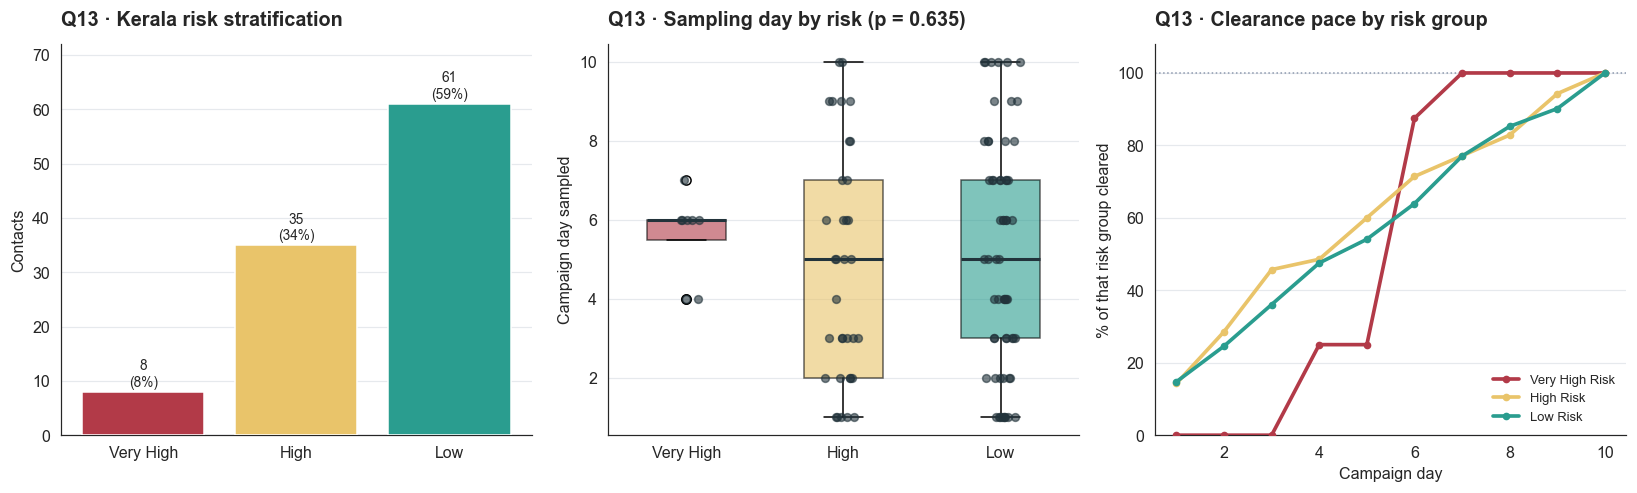

In [17]:
kerala = contacts[contacts["outbreak"].str.contains("Kerala")].copy()
kerala["campaign_day"] = (kerala["date_sample"] - kerala["date_sample"].min()).dt.days + 1

risk_order = ["Very High Risk", "High Risk", "Low Risk"]
summary = (kerala.groupby("risk_category")
           .agg(contacts=("contact_id", "size"),
                mean_day=("campaign_day", "mean"),
                median_day=("campaign_day", "median"),
                mean_age=("age", "mean"))
           .reindex(risk_order))

print("KERALA RISK STRATIFICATION vs SAMPLING ORDER")
print("=" * 74)
print(summary.to_string(float_format=lambda v: f"{v:.2f}"))

groups = [kerala.loc[kerala["risk_category"] == r, "campaign_day"].to_numpy()
          for r in risk_order]
h_stat, p_kw = stats.kruskal(*groups)
print(f"\nKruskal-Wallis, sampling day by risk category : H = {h_stat:.3f}, p = {p_kw:.4f}")
print(f"  -> {'risk DID drive order' if p_kw < 0.05 else 'risk did NOT drive sampling order'}")

vh = kerala.loc[kerala["risk_category"] == "Very High Risk", "campaign_day"]
lo = kerala.loc[kerala["risk_category"] == "Low Risk", "campaign_day"]
u_vh, p_vh = stats.mannwhitneyu(vh, lo)
print(f"\nVery High Risk (mean day {vh.mean():.2f}) vs Low Risk (mean day {lo.mean():.2f})")
print(f"  Mann-Whitney U = {u_vh:.1f}, p = {p_vh:.4f}")

print("\nRISK CATEGORY BY EXPOSURE SETTING")
print("=" * 74)
print(pd.crosstab(kerala["risk_category"], kerala["contact_type"])
      .reindex(risk_order).to_string())

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.6))

risk_colors = {"Very High Risk": C["death"], "High Risk": C["warn"], "Low Risk": C["good"]}

ax = ax1
bars = ax.bar(range(3), summary["contacts"],
              color=[risk_colors[r] for r in risk_order], zorder=3)
for bar, val in zip(bars, summary["contacts"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 1,
            f"{int(val)}\n({val / len(kerala) * 100:.0f}%)", ha="center", fontsize=9)
ax.set_xticks(range(3))
ax.set_xticklabels([r.replace(" Risk", "") for r in risk_order])
ax.set_ylim(0, 72)
style_axes(ax, ylabel="Contacts", title="Q13 · Kerala risk stratification")

ax = ax2
bp = ax.boxplot(groups, labels=[r.replace(" Risk", "") for r in risk_order],
                patch_artist=True, widths=0.5, medianprops=dict(color=C["dark"], lw=2))
for patch, r in zip(bp["boxes"], risk_order):
    patch.set_facecolor(risk_colors[r])
    patch.set_alpha(0.6)
rng = np.random.default_rng(11)
for i, vals in enumerate(groups, start=1):
    ax.scatter(rng.normal(i, 0.06, len(vals)), vals, s=26, color=C["dark"], alpha=0.6, zorder=4)
style_axes(ax, ylabel="Campaign day sampled",
           title=f"Q13 · Sampling day by risk (p = {p_kw:.3f})")

ax = ax3
for r in risk_order:
    sub = kerala[kerala["risk_category"] == r]
    daily = sub.groupby("campaign_day").size().reindex(range(1, 11), fill_value=0)
    ax.plot(daily.index, daily.cumsum() / daily.sum() * 100, lw=2.4, marker="o", ms=4,
            color=risk_colors[r], label=r, zorder=3)
ax.axhline(100, color=C["muted"], ls=":", lw=1)
ax.set_ylim(0, 108)
style_axes(ax, ylabel="% of that risk group cleared", xlabel="Campaign day",
           title="Q13 · Clearance pace by risk group")
ax.legend(fontsize=8.5, loc="lower right")
fig.tight_layout()
save_fig(fig, "q13_risk_stratification")
plt.show()

### Analysis

**The risk classification was recorded but not acted upon. Sampling order was
effectively random with respect to risk — and the highest-risk group was sampled
*last*.**

| Risk category | Contacts | Share | Mean sampling day | Median |
|---|---|---|---|---|
| **Very High Risk** | 8 | 7.7% | **5.62** | 6.0 |
| **High Risk** | 35 | 33.7% | **4.77** | 5.0 |
| **Low Risk** | 61 | 58.7% | **5.07** | 5.0 |

**Kruskal-Wallis: H = 0.907, p = 0.635.** No relationship between assigned risk and
when a contact was actually sampled. The direct Very-High-versus-Low comparison
confirms it (Mann-Whitney p = 0.578), and the sign runs the wrong way: **the eight
Very High Risk contacts were sampled on average 0.85 days *later* than Low Risk
contacts.**

**How much does this matter in practice?** Honestly — in this instance, not much,
and the notebook should not overstate it. The entire campaign ran 10 days and
cleared the full cohort inside the incubation window (Q10), so no contact was
meaningfully delayed in absolute terms and the outcome was 0 positives (Q12). With
only 8 Very High Risk contacts, this test also has very little power; a real
prioritisation effect of modest size would not be detectable here.

**But the process finding is still worth acting on, for two reasons.**

First, **this campaign was small enough that sequencing did not bind.** A cohort of
104 clears comfortably in 10 days regardless of order. A cohort of 500 — the scale
Siliguri 2001 would demand today — cannot, and then the order of sampling directly
determines who is detected in time to be isolated. A prioritisation protocol that
has never been exercised on a small outbreak will not materialise on a large one.

Second, **the stratification itself looks sound**, which makes not using it more of
a waste. The Very High Risk group is exactly who it should be: only 1 of the 8 is a
healthcare worker (who have PPE), while 3 are community and 3 workplace contacts —
unprotected, close-proximity exposures. Their mean age of 27.6 is well below the
cohort's 36.8, consistent with younger household and workplace contacts. The
classification is capturing genuine risk; it simply is not being used to sequence
the queue.

**Recommendation.** Make risk category the explicit sort key for sample collection,
with a stated service level — *Very High and High Risk sampled within 48 hours of
identification, Low Risk within 7 days.* Kerala's field teams demonstrably had the
throughput to meet that target (Q11); they simply were not asked to. This is a
zero-cost protocol change that converts an already-collected data field into an
operational control, and it is the kind of discipline that only matters on the day
it matters enormously.

---
## Q14. Where does Nipah keep coming back, and by which routes?

**Business context.** Geographic recurrence identifies where to place permanent
capability. Route composition identifies which intervention — sap safety, hospital
infection control, or habitat separation — buys the most prevention per rupee.

THE FOUR EPIDEMIOLOGICAL THEATRES
                                 events  cases  deaths  first_year  last_year  cfr
theatre                                                                           
Bangladesh — named district          11    175     134        2001       2026 76.6
Bangladesh — multiple districts       7    131      96        2011       2023 73.3
India — West Bengal                   3     73      51        2001       2026 69.9
India — Kerala                        7     34      24        2018       2026 70.6

KERALA — seven events in nine years
 year                      location  cases  deaths  cfr_recomputed
 2018            Kerala (Kozhikode)     19      17            89.5
 2019                Kerala (Kochi)      1       0             0.0
 2021            Kerala (Kozhikode)      1       1           100.0
 2023            Kerala (Kozhikode)      6       2            33.3
 2024           Kerala (Malappuram)      2       2           100.0
 2025 Kerala (Malappuram, Pal

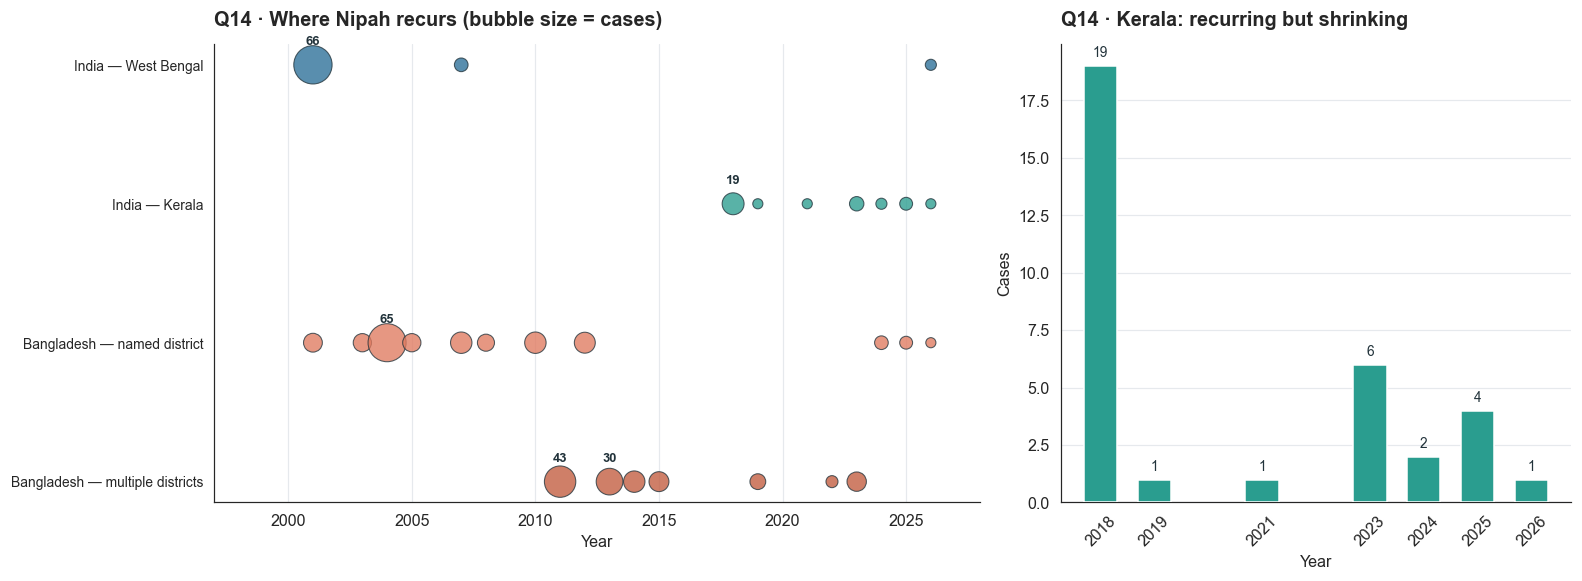

In [18]:
focus_events = events[events["is_focus_country"]].copy()


def region_group(location: str) -> str:
    """Group outbreak locations into the four epidemiological theatres."""
    text = location.lower()
    if "multiple" in text:
        return "Bangladesh — multiple districts"
    if any(k in text for k in ("kerala", "kozhikode", "malappuram", "kochi", "palakkad")):
        return "India — Kerala"
    if any(k in text for k in ("siliguri", "nadia", "barasat", "west bengal")):
        return "India — West Bengal"
    return "Bangladesh — named district"


focus_events["theatre"] = focus_events["location"].map(region_group)
theatre = (focus_events.groupby("theatre")
           .agg(events=("year", "size"), cases=("cases", "sum"), deaths=("deaths", "sum"),
                first_year=("year", "min"), last_year=("year", "max"))
           .assign(cfr=lambda d: d["deaths"] / d["cases"] * 100)
           .sort_values("cases", ascending=False))

print("THE FOUR EPIDEMIOLOGICAL THEATRES")
print("=" * 92)
print(theatre.to_string(float_format=lambda v: f"{v:.1f}"))

print("\nKERALA — seven events in nine years")
print("=" * 74)
print(focus_events[focus_events["theatre"] == "India — Kerala"]
      [["year", "location", "cases", "deaths", "cfr_recomputed"]]
      .to_string(index=False, float_format=lambda v: f"{v:.1f}"))

print("\nWEST BENGAL — three events in 26 years")
print("=" * 74)
print(focus_events[focus_events["theatre"] == "India — West Bengal"]
      [["year", "location", "cases", "deaths", "cfr_recomputed"]]
      .to_string(index=False, float_format=lambda v: f"{v:.1f}"))

print("\nNAOGAON DISTRICT — a recurring Bangladeshi hotspot")
print("=" * 74)
print(focus_events[focus_events["location"].str.contains("Naogaon", case=False)]
      [["year", "location", "cases", "deaths"]].to_string(index=False))

print("\n2026 — all three principal transmission routes in a single year")
print("=" * 100)
print(cases[["case_id", "outbreak", "exposure_source", "onset_month", "final_status"]]
      .to_string(index=False))

# --- Chart ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.4),
                               gridspec_kw={"width_ratios": [1.5, 1]})

theatre_colors = {
    "Bangladesh — named district": C["bangladesh"],
    "Bangladesh — multiple districts": "#C25B3D",
    "India — Kerala": C["good"],
    "India — West Bengal": C["india"],
}
for name, group in focus_events.groupby("theatre"):
    ax1.scatter(group["year"], [name] * len(group), s=group["cases"] * 9 + 35,
                color=theatre_colors[name], alpha=0.78, edgecolor=C["dark"],
                linewidth=0.7, zorder=3)
    for _, row in group.iterrows():
        if row["cases"] >= 19:
            ax1.annotate(f"{int(row['cases'])}", xy=(row["year"], name),
                         xytext=(0, 13), textcoords="offset points",
                         ha="center", fontsize=8.5, fontweight="bold", color=C["dark"])
ax1.set_xlim(1997, 2028)
style_axes(ax1, xlabel="Year", title="Q14 · Where Nipah recurs (bubble size = cases)", ygrid=False)
ax1.tick_params(axis="y", labelsize=9)

kerala_ev = focus_events[focus_events["theatre"] == "India — Kerala"].sort_values("year")
ax2.bar(kerala_ev["year"], kerala_ev["cases"], color=C["good"], width=0.62, zorder=3)
for _, row in kerala_ev.iterrows():
    ax2.text(row["year"], row["cases"] + 0.4, f"{int(row['cases'])}",
             ha="center", fontsize=9, color=C["dark"])
ax2.set_xticks(kerala_ev["year"])
ax2.tick_params(axis="x", rotation=45)
style_axes(ax2, ylabel="Cases", xlabel="Year",
           title="Q14 · Kerala: recurring but shrinking")
fig.tight_layout()
save_fig(fig, "q14_geography_routes")
plt.show()

### Analysis

**Four distinct theatres, and they demand four different answers.**

| Theatre | Events | Cases | Pooled CFR | Span |
|---|---|---|---|---|
| **Bangladesh — named district** | 11 | **175** | **76.6%** | 2001–2026 |
| **Bangladesh — multiple districts** | 7 | 131 | 73.3% | 2011–2023 |
| **India — West Bengal** | 3 | 73 | 69.9% | 2001–2026 |
| **India — Kerala** | 7 | 34 | 70.6% | **2018–2026** |

**Kerala is the clearest signal in the geographic data: seven events in nine
years, and shrinking.** 2018: 19 cases → 2019: 1 → 2021: 1 → 2023: 6 → 2024: 2 →
2025: 4 → **2026: 1, with zero deaths.** Kerala has gone from a single devastating
19-case outbreak with 89.5% lethality to near-annual single-case detections.

**This is the most encouraging pattern in the entire dataset, and it is a
detection story rather than a spillover story.** Kerala did not start having Nipah
in 2018 — it started *finding* it in 2018, and has since built the reflex to test
early (Q9: 1-day confirmation) and trace immediately (Q10: same-day activation).
The falling case counts are what early detection looks like: each introduction is
caught before it amplifies. **Kerala is the operational model the rest of the region
should be measured against.**

**West Bengal is the opposite pattern — and Q9 explains why.** Three events in 26
years: Siliguri 2001 (66 cases), Nadia 2007 (5 cases, 100% CFR), Barasat 2026 (2
cases). Rare enough that clinical suspicion never becomes reflexive, which is
exactly why Barasat took 8 days to confirm while Kozhikode took 1. **Rarity is
itself the risk factor.**

**Naogaon district recurs across the full record — 2003, 2025 and 2026** — which is
what a stable environmental reservoir combined with a persistent cultural practice
looks like. Bangladesh's named-district theatre also carries the highest lethality
in the region at 76.6%, reflecting rural distance from tertiary care (Q9: the
Naogaon patient was confirmed a day after death).

**2026 is unusual and instructive: all three principal transmission routes appeared
within a single year.**

| Route | Outbreak | Onset | Outcome |
|---|---|---|---|
| **Nosocomial** (hospital) | West Bengal, 2 nurses | December | 1 died, 1 recovered |
| **Foodborne** (raw date-palm sap) | Bangladesh, Naogaon | January | Died |
| **Environmental** (bat-roost exposure) | Kerala, disused godown | May | Survived |

And the contact data independently corroborates each stated route (Q12): West
Bengal's cohort was 71.4% hospital-linked, Bangladesh's was 100% community, and
Kerala's included 21.2% workplace contacts consistent with an occupational
environmental exposure. **The exposure histories and the traced cohorts tell the
same story, which is a meaningful internal validation of the dataset.**

**The seasonal signal is visible even at n = 4**: three of the four onsets fall in
**December–January**, inside the date-palm-sap harvest window, while the Kerala
environmental case falls in **May**, outside it. This is consistent with the
established seasonality but must not be over-read — four cases cannot establish
seasonality on their own, and the historical file carries no month field to test it
properly. **Acquiring onset months for historical outbreaks is the single highest-value
addition that could be made to this dataset.**

**Recommendation — route-matched interventions:**

1. **Bangladesh (sap route, 76.6% CFR, recurs annually):** seasonal sap-safety
   campaigns and bamboo skirts on tapping pots, timed to December–April. Highest
   burden, highest lethality, most predictable timing.
2. **West Bengal (nosocomial, rare, explosive):** standing infection-control
   readiness in district hospitals and a lower NiV testing threshold — the Barasat
   8-day delay is the specific gap to close.
3. **Kerala (environmental, frequent, well-controlled):** sustain the current model.
   It is working, and it should be exported.

---
# Part C — Polynomial regression modelling

---
## Q15. What does a polynomial trend model project for 2027 — and how much should we trust it?

**Business context.** A planning cycle needs a number for next year. This section
produces one, and — just as importantly — establishes how much weight it can bear.

**Why polynomial regression is the right family here.** Q6 showed the series is
stationary with **no autocorrelation at any lag**, which rules out ARIMA and
lag-feature models: there is no temporal dependence structure to estimate. Q7 showed
the underlying level is **not monotonic** but bimodal, which rules out simple linear
regression. What remains is a smooth function of calendar time, and a polynomial
with the degree chosen by cross-validation is the smallest such curve the data will
support.

**The models are trained by `src/train_models.py`** and persisted to `models/`. Each
one searches **degree (1–6) × ridge penalty × variance-stabilising transform**,
selected by leave-one-out CV and always scored back on the original scale, so a
log-space fit and a raw-space fit compete on the same yardstick. Crucially, every
model is also compared against a **"predict the historical mean" baseline** — and that
baseline is itself put through the *same* leave-one-out split, so an out-of-sample model
is never scored against an in-sample null.

In [19]:
# Retrain from scratch so the notebook is self-contained and reproducible.
summary = tm.train_and_save(verbose=True)

print("\n\nMODEL SCORECARD")
print("=" * 118)
scorecard = summary[["target", "transform", "degree", "alpha", "n_obs",
                     "cv_r2", "cv_rmse", "baseline_rmse", "beats_mean",
                     "train_r2", "adj_r2"]]
print(scorecard.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("\nONE-YEAR-AHEAD PROJECTIONS FOR 2027")
print("=" * 100)
proj = summary[summary["forecastable"]][
    ["target", "next_year_pred", "next_year_lo95", "next_year_hi95",
     "beats_mean", "extrapolation_risk"]]
print(proj.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\n(cases_trend_ma5 is a smoothing target and is deliberately excluded:")
print(" its final points come from truncated windows, so extrapolating it")
print(" would produce an artefact rather than a projection.)")

curves = pd.read_csv(OUTPUT_DIR / "model_fitted_curves.csv")
grid_search = pd.read_csv(OUTPUT_DIR / "model_degree_search.csv")

[         cases_total] identity deg=3 alpha=10.0 CV-R2=-0.087 CV-RMSE= 19.74 vs  19.61 (NO better than mean)  2027: 3.62 [0.0, 25.9]


[        deaths_total] identity deg=3 alpha=10.0 CV-R2=-0.077 CV-RMSE= 14.56 vs  14.53 (NO better than mean)  2027: 2.34 [0.0, 18.8]


[     cases_trend_ma5] identity deg=6 alpha=0.0  CV-R2= 0.546 CV-RMSE=  5.53 vs   8.49 (beats mean)


[cases_outbreak_years]    log1p deg=5 alpha=0.0  CV-R2= 0.304 CV-RMSE= 16.42 vs  20.72 (beats mean)  2027: 6.15 [0.0, 213.7]


[  cfr_outbreak_years] identity deg=1 alpha=10.0 CV-R2=-0.189 CV-RMSE= 16.57 vs  15.99 (NO better than mean)  2027: 73.30 [64.2, 83.8]


[    cases_bangladesh] identity deg=5 alpha=0.1  CV-R2= 0.042 CV-RMSE= 14.19 vs  15.02 (beats mean)  2027: 6.68 [0.0, 35.6]


[         cases_india]    log1p deg=5 alpha=10.0 CV-R2=-0.075 CV-RMSE= 12.79 vs  12.78 (NO better than mean)  2027: 3.98 [1.6, 12.1]

Saved 7 models to C:\Users\rafae.RAFAEL_NOTEBOOK\OneDrive\Documentos\Projetos_data_science_IA\kaggle\Projetos_kaggle\Nipah Virus Outbreaks 2025-2026 India & Bangladesh\models


MODEL SCORECARD
              target transform  degree  alpha  n_obs  cv_r2  cv_rmse  baseline_rmse  beats_mean  train_r2  adj_r2
         cases_total  identity       3 10.000     29 -0.087   19.737         19.607       False     0.063  -0.049
        deaths_total  identity       3 10.000     29 -0.077   14.561         14.532       False     0.067  -0.045
     cases_trend_ma5  identity       6  0.000     29  0.546    5.526          8.494        True     0.714   0.636
cases_outbreak_years     log1p       5  0.000     20  0.304   16.421         20.716        True     0.575   0.423
  cfr_outbreak_years  identity       1 10.000     20 -0.189   16.569         15.995       False     0.0

### Analysis

**Four of the seven models fail to beat "predict the historical mean" — and that is
the headline result, exactly as Q6 predicted.**

| Target | Transform | Degree | CV R² | CV RMSE | Baseline | Beats mean? |
|---|---|---|---|---|---|---|
| `cases_total` | identity | 3 | **−0.087** | 19.74 | 19.61 | **No** |
| `deaths_total` | identity | 3 | −0.077 | 14.56 | 14.53 | **No** |
| `cases_trend_ma5` | identity | 6 | **+0.546** | 5.53 | 8.49 | **Yes** |
| `cases_outbreak_years` | **log1p** | 5 | **+0.304** | 16.42 | 20.72 | **Yes** |
| `cfr_outbreak_years` | identity | 1 | −0.189 | 16.57 | 15.99 | **No** |
| `cases_bangladesh` | identity | 5 | +0.042 | 14.19 | 15.02 | Marginally |
| `cases_india` | log1p | 5 | −0.075 | 12.79 | 12.78 | Dead heat |

**`cases_india` is a dead heat** (12.791 vs 12.778): its curve and a flat mean line are
indistinguishable out of sample.

**A negative cross-validated R² is not a bug — it is the correct answer.** It means
the fitted curve predicts held-out years *worse* than simply quoting the historical
average. For `cases_total`, the flagship target, that is precisely what happens:
**CV R² = −0.087.** The model is worse than useless for predicting any individual
year's count.

**This is Q6's finding arriving through a completely independent route.** No
autocorrelation, a stationary series, and 26:1 overdispersion together mean the
year-to-year variation *is* noise. A model cannot extract signal that is not there,
and a model that appears to do so is overfitting. The honest conclusion is that
**the level of any individual year is not predictable from calendar time.**

**Two models do carry genuine signal, and it is worth being precise about what they
predict.**

- **`cases_trend_ma5` (CV R² = +0.546)** — this predicts the *smoothed* level, not
  any actual year. It confirms Q7's two-wave shape is a real structure rather than
  a smoothing artefact. It is deliberately excluded from forecasting.
- **`cases_outbreak_years` (CV R² = +0.304)** — this is the most interesting result
  in Part C. By conditioning on `cases > 0`, it removes the zero-inflation and asks
  a cleaner question: *given that an outbreak happens, how large is it?* That
  quantity **is** predictable, and it is declining. The `log1p` transform winning
  here is exactly what right-skewed count data should prefer.

**That split vindicates the framing set up in Section 3: this series is a mixture
of two processes.** Modelling "cases per calendar year" blends *whether* an outbreak
occurs with *how big it is* and predicts neither. Separating them makes one of the
two components tractable.

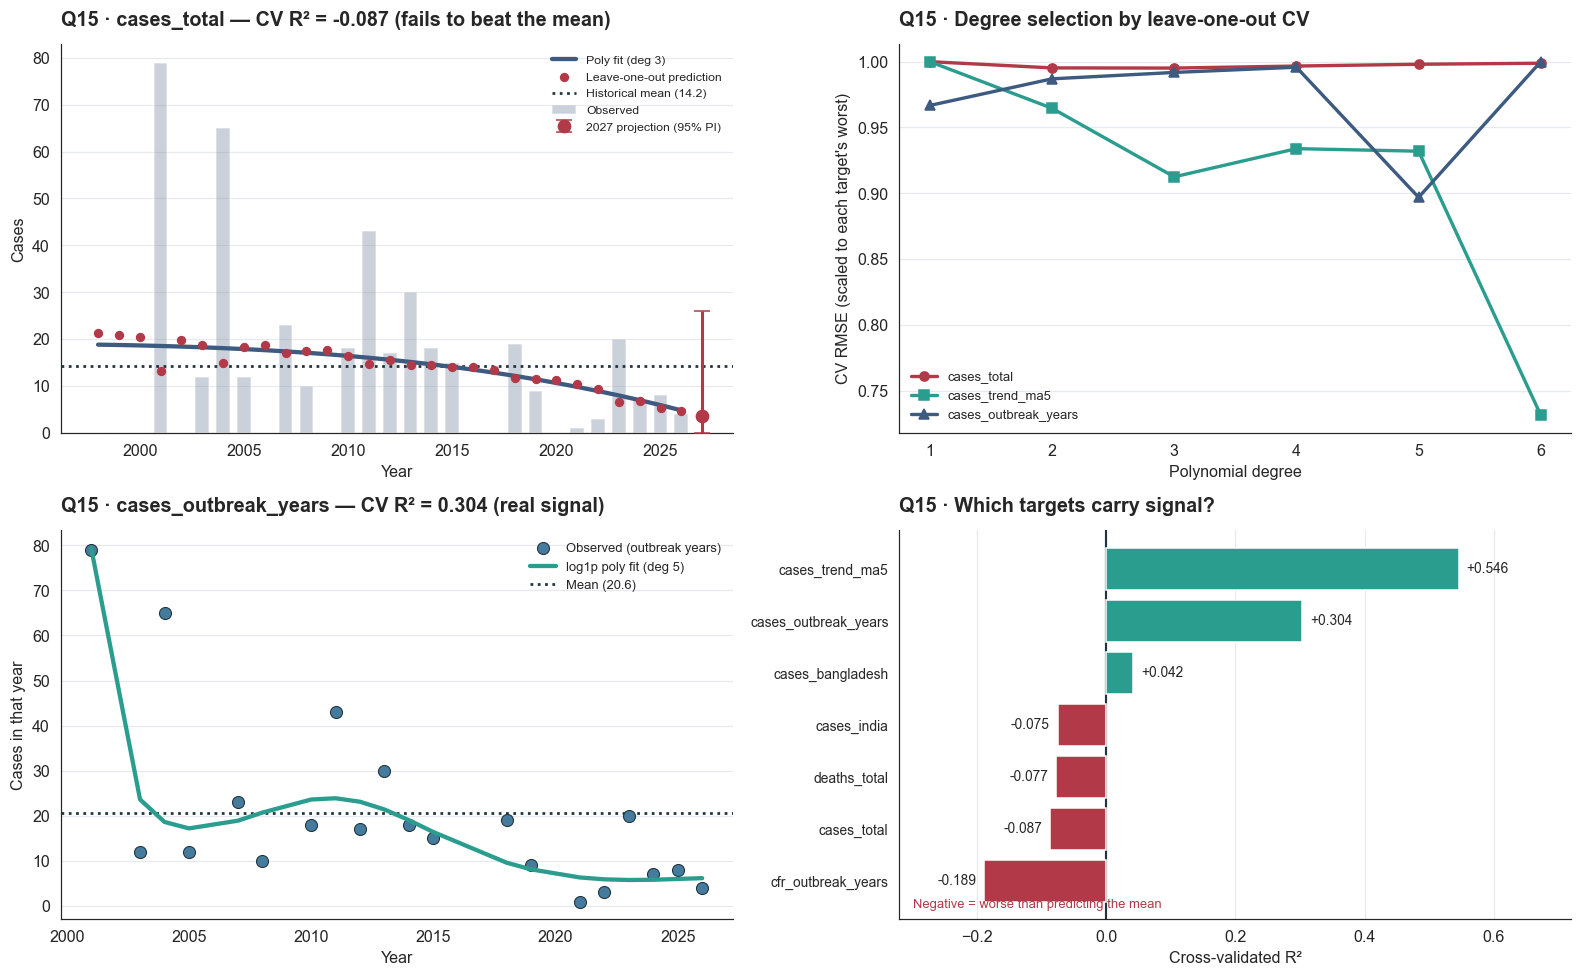

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14.5, 9))

# --- Panel 1: the flagship model that does NOT work ----------------------
ax = axes[0, 0]
ct_curve = curves[curves["target"] == "cases_total"]
row = summary[summary["target"] == "cases_total"].iloc[0]
ax.bar(ct_curve["year"], ct_curve["observed"], color=C["muted"], alpha=0.45,
       width=0.66, label="Observed", zorder=2)
ax.plot(ct_curve["year"], ct_curve["fitted"], color=C["accent"], lw=2.8,
        label=f"Poly fit (deg {int(row['degree'])})", zorder=4)
ax.scatter(ct_curve["year"], ct_curve["loo_pred"], s=26, color=C["death"],
           zorder=5, label="Leave-one-out prediction")
ax.axhline(ct_curve["observed"].mean(), color=C["dark"], ls=":", lw=1.8,
           label=f"Historical mean ({ct_curve['observed'].mean():.1f})", zorder=3)
ax.errorbar(2027, row["next_year_pred"],
            yerr=[[row["next_year_pred"] - row["next_year_lo95"]],
                  [row["next_year_hi95"] - row["next_year_pred"]]],
            fmt="o", color=C["death"], ms=8, capsize=5, lw=2, zorder=6,
            label="2027 projection (95% PI)")
style_axes(ax, ylabel="Cases", xlabel="Year",
           title=f"Q15 · cases_total — CV R² = {row['cv_r2']:.3f} (fails to beat the mean)")
ax.legend(fontsize=8, loc="upper right")

# --- Panel 2: degree selection -------------------------------------------
ax = axes[0, 1]
for target, colour, marker in [("cases_total", C["death"], "o"),
                               ("cases_trend_ma5", C["good"], "s"),
                               ("cases_outbreak_years", C["accent"], "^")]:
    sub = (grid_search[grid_search["target"] == target]
           .groupby("degree")["cv_rmse"].min())
    normalised = sub / sub.max()
    ax.plot(normalised.index, normalised.to_numpy(), color=colour, lw=2.2,
            marker=marker, ms=6, label=target, zorder=3)
style_axes(ax, ylabel="CV RMSE (scaled to each target's worst)", xlabel="Polynomial degree",
           title="Q15 · Degree selection by leave-one-out CV")
ax.legend(fontsize=8.5)

# --- Panel 3: the model that DOES work ------------------------------------
ax = axes[1, 0]
ob_curve = curves[curves["target"] == "cases_outbreak_years"]
row_ob = summary[summary["target"] == "cases_outbreak_years"].iloc[0]
ax.scatter(ob_curve["year"], ob_curve["observed"], s=62, color=C["case"],
           edgecolor=C["dark"], linewidth=0.7, zorder=4, label="Observed (outbreak years)")
ax.plot(ob_curve["year"], ob_curve["fitted"], color=C["good"], lw=2.8,
        label=f"log1p poly fit (deg {int(row_ob['degree'])})", zorder=5)
ax.axhline(ob_curve["observed"].mean(), color=C["dark"], ls=":", lw=1.8,
           label=f"Mean ({ob_curve['observed'].mean():.1f})", zorder=3)
style_axes(ax, ylabel="Cases in that year", xlabel="Year",
           title=f"Q15 · cases_outbreak_years — CV R² = {row_ob['cv_r2']:.3f} (real signal)")
ax.legend(fontsize=8.5, loc="upper right")

# --- Panel 4: scorecard ---------------------------------------------------
ax = axes[1, 1]
sc = summary.sort_values("cv_r2")
colours = [C["good"] if v > 0 else C["death"] for v in sc["cv_r2"]]
bars = ax.barh(range(len(sc)), sc["cv_r2"], color=colours, zorder=3)
for i, (bar, val) in enumerate(zip(bars, sc["cv_r2"])):
    offset = 0.012 if val >= 0 else -0.012
    ax.text(val + offset, i, f"{val:+.3f}", va="center",
            ha="left" if val >= 0 else "right", fontsize=9)
ax.axvline(0, color=C["dark"], lw=1.4)
ax.set_yticks(range(len(sc)))
ax.set_yticklabels(sc["target"], fontsize=9)
ax.set_xlim(-0.32, 0.72)
style_axes(ax, xlabel="Cross-validated R²",
           title="Q15 · Which targets carry signal?", ygrid=False)
ax.text(0.02, 0.03, "Negative = worse than predicting the mean",
        transform=ax.transAxes, fontsize=8.5, color=C["death"])
fig.tight_layout()
save_fig(fig, "q15_polynomial_models")
plt.show()

### Analysis

**The four panels together tell the whole modelling story.**

**Panel 1 — why `cases_total` fails.** The fitted curve (blue) is nearly flat,
because leave-one-out CV chose degree 3 with the *strongest* available ridge penalty
(α = 10). Cross-validation looked at every more expressive option and concluded that
the safest curve is one that barely moves. The red leave-one-out points scatter
wildly around it — those are the model's honest out-of-sample predictions, and they
are worse than the dotted mean line. **The model's own selection process is telling
us not to trust its shape.**

**Panel 2 — the degree-selection curves diverge, which is the diagnostic.** For
`cases_total`, CV RMSE is essentially flat across degrees 1–6: no polynomial order
helps, because there is nothing to fit. For `cases_trend_ma5`, RMSE falls steadily
with degree, because the smoothed series has genuine curvature to capture. **When
adding flexibility does not improve held-out error, the answer is that the signal
is absent, not that the model is too simple.**

**Panel 3 — the model that works.** Restricted to the 20 outbreak years and fitted
on the log scale, the curve tracks a real declining trajectory in outbreak
magnitude: from roughly 20–40 cases in the early 2000s down to single digits in the
2020s. CV R² = +0.304 means it explains about 30% of out-of-sample variance in
*outbreak size given an outbreak occurred*.

**Panel 4 — the scorecard.** Only two targets sit meaningfully above zero. Four sit
below it. This is an unusual thing to publish, and publishing it is the point: a
notebook that reported only the two working models would imply that Nipah annual
counts are forecastable, and they are not.

---

### The 2027 projection — and its health warning

Intervals are **residual bootstrap** (2,000 resamples), not the analytic
`±1.96·σ`. The companion ML notebook backtests both over 2010–2026: the bootstrap
achieves **94.1% coverage at a mean width of 38.5**, while the analytic form
over-covers at **100% and width 60.0** because it assumes normal residuals that
Shapiro–Wilk rejects (p = 0.0002).

| Target | 2027 point estimate | 95% bootstrap PI | (analytic, for reference) | Trustworthy? |
|---|---|---|---|---|
| `cases_total` | **3.62 cases** | **0 – 25.9** | 0 – 42.3 | **No** — fails vs baseline |
| `deaths_total` | 2.34 deaths | 0 – 18.8 | 0 – 31.0 | **No** |
| `cases_outbreak_years` | 6.15 cases | **0 – 213.7** | 0 – 36.2 | Conditionally |
| `cfr_outbreak_years` | 73.30% | **64.2 – 83.8** | 42.0 – **104.6** | **No** |

**Even the tightened interval is enormous.** `cases_total` spans **0 to 26 cases** —
still most of the recent historical range. A plan that must work across it is not
being informed by this model.

**Two entries in that table earn their keep.** The analytic CFR interval reached
**104.6%**, which is impossible for a case fatality ratio: a polynomial has no
concept of a bounded proportion. The bootstrap returns **[64.2, 83.8]** with no
constraint added, because resampling observed residuals cannot manufacture values
the data never supports. Conversely, `cases_outbreak_years` gets *wider* under
bootstrap (0–213.7 vs 0–36.2) — that is the degree-5 `log1p` model's genuine
instability under resampling, which the analytic σ was hiding.

**Two further structural cautions:**

1. **Extrapolation risk.** Four of the seven models selected degree ≥ 4, flagged in
   the registry as `extrapolation_risk`. High-degree polynomials bend violently
   outside their fitted range. `cases_trend_ma5` demonstrates this vividly: its
   degree-6 curve dives below zero immediately past 2026, which is why it is
   excluded from forecasting entirely rather than quietly clipped.
2. **Regime blending (the most important caveat).** Every model fits 1998–2026 as a
   single homogeneous process. **Q8 showed it is not** — there is a break around
   2015, with a pre-break mean of 22.8 cases/year and a post-break mean of 6.45. A
   curve fitted across both describes neither, and its 2027 estimate is pulled
   upward by a regime that ended a decade ago.

---

### So what number should actually go into the 2027 plan?

**Not the model's.** The defensible answer comes from the descriptive analysis, not
the regression:

| Quantity | Value | Source |
|---|---|---|
| **Expected cases in 2027** | **~6–7** | Q8 post-2015 regime mean (6.45/yr) |
| **Probability 2027 is active** | **~80%** | Q5 recent activity rate |
| **Expected deaths** | **~5** | 6.5 cases × 73.8% pooled CFR (Q3) |
| **Surge design point** | **30–40 cases** | Q7/Q8 post-break maximum + headroom |
| **Contacts to trace per case** | **~100** | Q11 |

**The polynomial models earn their place in this notebook by establishing what is
*not* knowable.** They were fitted properly, validated honestly, and four of them
were reported as failures. That result — *the level of any individual year is not
predictable from calendar time* — is itself the finding that protects a planner from
a false-precision forecast, and it is more valuable than a confident number would
have been.

---
## 4. Exporting the analytical artefacts

In [21]:
exports = {
    "annual_time_series.csv": annual,
    "annual_by_country.csv": by_country,
    "case_timelines_2026.csv": cases,
    "contacts_harmonised.csv": contacts,
    "surveillance_daily_curve.csv": surveillance,
    "tracing_efficiency.csv": tracing,
    "outbreak_events.csv": events,
}

print("EXPORTED TO output/")
print("=" * 70)
for filename, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)
    print(f"  {filename:<32s} {frame.shape[0]:>4d} rows x {frame.shape[1]:>2d} cols")

print("\nMODEL ARTEFACTS IN models/")
print("=" * 70)
for path in sorted(MODELS_DIR.glob("*")):
    print(f"  {path.name:<34s} {path.stat().st_size / 1024:>7.1f} KB")

print("\nFIGURES IN img/")
print("=" * 70)
for path in sorted(IMG_DIR.glob("*.png")):
    print(f"  {path.name:<34s} {path.stat().st_size / 1024:>7.1f} KB")

EXPORTED TO output/
  annual_time_series.csv             29 rows x 21 cols
  annual_by_country.csv              58 rows x 19 cols
  case_timelines_2026.csv             4 rows x 23 cols
  contacts_harmonised.csv           331 rows x 15 cols
  surveillance_daily_curve.csv       17 rows x  7 cols
  tracing_efficiency.csv              3 rows x 12 cols
  outbreak_events.csv                31 rows x 11 cols

MODEL ARTEFACTS IN models/
  model_registry.json                    6.7 KB
  poly_cases_bangladesh.joblib           1.6 KB
  poly_cases_india.joblib                1.6 KB
  poly_cases_outbreak_years.joblib       1.7 KB
  poly_cases_total.joblib                1.5 KB
  poly_cases_trend_ma5.joblib            1.7 KB
  poly_cfr_outbreak_years.joblib         1.5 KB
  poly_deaths_total.joblib               1.5 KB

FIGURES IN img/
  ml01_dataset.png                      91.5 KB
  ml02_conditioning.png                 78.9 KB
  ml03_transforms.png                   61.0 KB
  ml04_bias_variance.p

### Analysis

Seven analytical tables are written to `output/`, three model-audit files
(`model_performance_summary.csv`, `model_fitted_curves.csv`,
`model_degree_search.csv`), seven serialised models plus a registry in `models/`,
and every figure in `img/`.

These are the same artefacts the Streamlit dashboard in `app/` reads. Because both
the dashboard and this notebook import `src/nipah_data.py` and `src/train_models.py`
rather than reimplementing anything, a correction made in the data layer propagates
to both without a manual reconciliation step.

---
# Conclusions

## The fifteen questions, answered

| # | Question | Answer |
|---|---|---|
| **Q1** | Is there a long-run trend? | **No monotonic trend** (Mann-Kendall τ = 0.000, p = 1.00). The Poisson GLM's p = 2×10⁻⁹ is an artefact of 26:1 overdispersion. |
| **Q2** | How concentrated is the burden? | **Extremely** — Gini 0.627; 2001 alone holds 19.1%; the top 3 years hold 45.3%. |
| **Q3** | Has lethality improved? | **No.** Pooled CFR 73.8%; 76.3% → 69.5% across halves, p = 0.130. |
| **Q4** | India vs Bangladesh? | **Same lethality, different rhythm.** Bangladesh active 62% of years vs India 31% (p = 0.018); CFR gap not significant. |
| **Q5** | How often does it return? | **Annually now.** 14 of 19 gaps are 1 year; 6 consecutive active years 2021–2026. |
| **Q6** | Does one year predict the next? | **No.** ACF(1) = −0.091, no significant lag, ADF p < 0.0001 (stationary). |
| **Q7** | What does smoothing reveal? | **Two waves, not a decline** — peak 33.6/yr (2003) → 6.3/yr (2026); SD fell 2.79×. |
| **Q8** | Is there a structural break? | **Probably, at 2015** — but Bonferroni p = 0.87. Mean 22.8 → 6.45 cases/yr. |
| **Q9** | How fast is detection? | Onset→admission **8.0 d** (immovable); admission→confirmation **1–9 d** (fixable). |
| **Q10** | How fast was tracing? | **Excellent** — activation in 0–1 days, full clearance inside the incubation window. |
| **Q11** | What capacity is needed? | **~100 contacts/case**; 25–30 samples/day; **no weekend slowdown** (p = 0.87). |
| **Q12** | Who was exposed, and who got infected? | **331 contacts, 0 positives.** West Bengal 71.4% hospital-linked. |
| **Q13** | Did risk stratification drive priority? | **No** (Kruskal-Wallis p = 0.635) — highest-risk contacts sampled *last*. |
| **Q14** | Where does it recur, and how? | Four theatres; **Kerala recurring but shrinking**; all three routes appeared in 2026. |
| **Q15** | What can be forecast? | **Not annual counts** (4 of 7 models lose to the mean). Outbreak *size given an outbreak* is predictable (CV R² = 0.304). |

## Five things a preparedness team should do

1. **Budget for a standing annual function, not an emergency response.** 80% of
   recent years are active and 2021–2026 was unbroken (Q5). Pre-position reagents
   and PPE before the December–April sap season; retain trained tracing teams
   between seasons.

2. **Close the admission-to-confirmation gap — it is the only controllable delay.**
   Kerala confirms in 1 day, Barasat took 8 (Q9). The fix is a lower testing
   threshold, not more laboratories: any acute encephalitis cluster in a healthcare
   worker should trigger NiV testing on day 1.

3. **Spend on prevention and speed, not on treatment.** Lethality has not moved in
   28 years and is not treatable downward (Q3). Every unit of survival benefit must
   be bought before infection — sap safety in Bangladesh, hospital infection control
   in West Bengal, habitat separation in Kerala (Q14).

4. **Size surge capacity to 30–40 cases and tracing to 100 contacts per case.** The
   post-2015 regime maximum is 30 (Q7/Q8); both Indian outbreaks converged on ~100
   contacts per case (Q11). The old 79-case design point is now oversized.

5. **Make risk category the sort key for sampling.** Kerala's stratification is
   sound but unused (Q13). A zero-cost protocol change — Very High and High Risk
   within 48 hours — that will only matter on the day it matters enormously.

## What this dataset cannot tell us

Being explicit about the limits is part of the analysis:

- **n = 29 annual observations.** Most tests in Part A are underpowered; several
  large effects (the 2015 break, the volatility drop) fail to reach significance
  despite substantial effect sizes. Absence of significance here is not evidence of
  absence.
- **No month field on historical outbreaks.** Seasonality — the single
  best-established feature of Nipah epidemiology — cannot be tested directly. Only
  four 2026 onset months are available. **This is the highest-value addition that
  could be made to the dataset.**
- **No denominators.** Cases are counted without populations at risk, so incidence
  rates cannot be computed and countries cannot be compared per capita.
- **Detection is confounded with incidence throughout.** Kerala's rising event count
  and falling case counts are consistent with better detection, better control, or
  both. No design in this dataset separates them.
- **The Bangladesh contact records carry no sampling dates**, so that outbreak
  cannot enter any of the daily surveillance analyses.

---

**Reproduce this analysis:**

```
python src/train_models.py                       # fit and persist the models
jupyter nbconvert --execute --inplace notebook/nipah_time_series_analysis.ipynb
streamlit run app/app.py                         # launch the dashboard
```